# HVAC Day-Ahead Energy Forecasting — Three Research Gaps beyond Xiao et al. (2022)
**Data:** EnergyDetective2020 (20 Shanghai office buildings, HVAC electricity, cooling seasons 2015–2017). **Split:** 2015 train → 2016 validation/calibration → 2017 out-of-sample test.
**Base paper:** Xiao, Gang, Yuan, Chen, Li, Wang & Feng (2022), *Energy and Buildings* 258, 111832.

## Research gaps (maximum three, each tied to evidence)
| Gap | What the base paper leaves open | Research question | Models / experiments in this notebook |
|---|---|---|---|
| **G1 — Information gap** | Inputs = previous-day load + 2 weather variables + calendar. No same-day-type weekly lag, no psychrometric (enthalpy, CDH) or other weather information. | **RQ1.** Which extra information actually reduces day-ahead error, and is the gain concentrated on Monday/weekend transitions? | `Phys_LSTM` + **feature-group ablation** (`Base+Lag168h`, `Base+Psychrometric`, …) + reference benchmarks (naive t-168 h, Ridge, Random Forest) |
| **G2 — Data-scarcity gap** | One model per building trained on ~122 days; the other buildings are never used. | **RQ2.** Does pooling the 20 buildings (area-normalised, metadata-conditioned) beat single-building models, and can it serve a **new building with zero local history**? | `Pooled_Base/Phys_LSTM`, `Global_NoMeta_LSTM`, `Global_Transfer_LSTM`, leave-one-building-out `ZeroShot_Pooled_Phys_LSTM` |
| **G3 — Deployment-realism gap** | Next-day weather is *observed* data presented as a forecast; only point forecasts; no uncertainty. | **RQ3.** How fast does accuracy degrade with realistic weather-forecast error, does noise-aware training help, and can calibrated intervals stay reliable under error and drift? | Autocorrelated forecast-error injection (σ = 0–4 °C), `Phys_NoiseAug_LSTM`, `NoWeather_LSTM`, split vs noise-matched vs **rolling conformal** intervals |

**Dropped as a gap (kept as an appendix ablation):** the anomaly-aware pipeline (IF/LOF features, input sanitisation, Huber). In the earlier run (seed 42) it was *worse* than the baseline: IF −10.4 %, LOF −18.3 %, IF+LOF −17.2 %, Sanitized_Robust −6.2 % mean MAE change, Consensus not significant (p = 0.45). That agrees with the base paper's own conclusion that cleaning/smoothing should be used with caution, so it is reported as a negative result, not claimed as a contribution.

**Evidence from the earlier run that motivates G1–G2** (seed 42, 20 buildings, MAE vs `Baseline_LSTM`): `Phys_LSTM` +5.3 % (17/20 buildings, p = 0.006); `Global_Transfer_LSTM` +12.1 % mean / +14.6 % median (17/20, p = 0.0001).

## What was refined compared with the previous version
1. Three gaps instead of four; anomaly sanitisation moved to an appendix ablation (negative result).
2. **Benchmarks added** (naive t-24 h / t-168 h, Ridge, Random Forest), so LSTM gains are judged against simple alternatives.
3. **Confounds removed:** Gap 1 feature-group ablation; Gap 2 pooled-without-metadata and metadata-removed global model; zero-shot leave-one-building-out.
4. **Data-quality rule** flags corrupted meters (Building 11: max ≈ 308 509 kWh; Building 19: 2017 mean collapses by > 90 %). Every table is reported for *All 20* and *Clean subset*.
5. **Statistics:** Wilcoxon with **Holm correction**, bootstrap 95 % CIs, Friedman omnibus test, multi-seed profile.
6. **New tables and figures (9–15)** for each gap, plus an Excel/CSV export of every table.
7. Fixed a latent bug: the progress print in Stage B/C indexed the baseline by position, which breaks with more than one seed.

> Set `RUN_PROFILE = "quick"` (1 seed, extra experiments on 8 buildings) first; use `"final"` (3 seeds, all 20 buildings) for the paper numbers.

In [6]:
!pip -q install chinese-calendar scikit-learn scipy

In [5]:
import os
import zipfile
import copy
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

# --------------------------------------------------
# DATASET UPLOAD OR AUTO-DETECTION
# --------------------------------------------------
extract_folder = Path("/content")
candidate_paths = [
    Path("/content/EnergyDetective2020-main/dataset"),
    Path("/content/EnergyDetective2020/dataset"),
    Path("./EnergyDetective2020-main/dataset"),
    Path("./dataset")
]

DATA_ROOT = next((p for p in candidate_paths if p.exists()), None)

if DATA_ROOT is None:
    try:
        from google.colab import files
        print("Please upload EnergyDetective2020-main.zip:")
        uploaded = files.upload()
        zip_name = next(
            (name for name in uploaded.keys() if name.lower().endswith(".zip")),
            None
        )
        if zip_name is not None:
            with zipfile.ZipFile(zip_name, "r") as zip_ref:
                zip_ref.extractall(extract_folder)
        DATA_ROOT = next((p for p in candidate_paths if p.exists()), None)
        if DATA_ROOT is None:
            # Fallback recursive search for ref_building_records.csv
            found = list(extract_folder.rglob("ref_building_records.csv"))
            if found:
                DATA_ROOT = found[0].parent.parent
    except ImportError:
        raise FileNotFoundError("Dataset folder not found. Place EnergyDetective2020-main/dataset in working directory.")

if DATA_ROOT is None or not DATA_ROOT.exists():
    raise FileNotFoundError("Could not locate dataset directory after extraction.")

print("Dataset folder:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())
print("GPU available:", torch.cuda.is_available())

Please upload EnergyDetective2020-main.zip:


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Saving EnergyDetective2020-main.zip to EnergyDetective2020-main.zip
Dataset folder: /content/EnergyDetective2020-main/dataset
Dataset exists: True
GPU available: False


## 1. Experiment Configuration & Hyperparameters

- **Representative Buildings**: `[3, 5, 9]` (matching the base paper's selected reference buildings).
- **Full Benchmark Scope**: All 20 Shanghai commercial office buildings (`0..19`).
- **Chronological Split**: `2015` (Train) -> `2016` (Validation & Conformal Calibration) -> `2017` (Out-of-Sample Test) across cooling seasons (`June 1 – September 30`).

In [7]:
RUN_PROFILE = "quick"   # "quick" = 1 seed, extra experiments on 8 buildings | "final" = 3 seeds, all 20 buildings
# --------------------------------------------------
# RESEARCH CONFIGURATION
# --------------------------------------------------
REPRESENTATIVE_BUILDINGS = [3, 5, 9]
ALL_BUILDINGS = list(range(20))

# Use [42] for fast verification; use [42, 43, 44] for multi-seed final reporting
SEEDS = [42, 43, 44] if RUN_PROFILE == "final" else [42]

# Forecasting horizon & split settings
LOOKBACK_HOURS = 24
FORECAST_HOURS = 24

TRAIN_YEAR = 2015
VALIDATION_YEAR = 2016
TEST_YEAR = 2017

COOLING_START_MONTH = 6
COOLING_START_DAY = 1
COOLING_END_MONTH = 9
COOLING_END_DAY = 30

# LSTM architecture hyperparameters
HIDDEN_SIZE = 100
NUM_LAYERS = 2
DROPOUT = 0.10

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 80
PATIENCE = 12
L1_LAMBDA = 1e-6

# Anomaly detection & sanitization settings
CONTAMINATION = 0.03
IF_TREES = 200
LOF_NEIGHBORS = 20
ROBUST_Z_THRESHOLD = 3.5

# Conformal prediction interval confidence level (90% interval -> alpha = 0.10)
CONFORMAL_ALPHA = 0.10

# Always enforce pathlib.Path for OUTPUT_DIR (fixes str / str TypeError)
OUTPUT_DIR = Path("/content/HVAC_Research_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR, "| Type:", type(OUTPUT_DIR))
print("Representative buildings:", REPRESENTATIVE_BUILDINGS)
print("Total buildings:", len(ALL_BUILDINGS))

# --------------------------------------------------
# REFINEMENT SETTINGS (new)
# --------------------------------------------------
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import itertools

SUBSET_BUILDINGS = sorted(set(REPRESENTATIVE_BUILDINGS + [0, 2, 4, 8, 16]))
EXTRA_BUILDINGS = ALL_BUILDINGS if RUN_PROFILE == "final" else SUBSET_BUILDINGS   # buildings used for ablation / robustness runs
LOBO_BUILDINGS = EXTRA_BUILDINGS if RUN_PROFILE == "final" else REPRESENTATIVE_BUILDINGS

NOISE_LEVELS = [0, 1, 2, 3, 4] if RUN_PROFILE == "final" else [0, 2, 4]   # weather-forecast error std (deg C)
NOISE_RHO = 0.9               # hour-to-hour autocorrelation of the forecast error
NOISE_TRAIN_SIGMA = 2.0       # noise level used for noise-aware training
N_AUG = 2                     # noisy copies of the training set added for noise-aware training
NOMINAL_LEVELS = [0.80, 0.90, 0.95]
ROLLING_CAL_DAYS = 28
print("Profile:", RUN_PROFILE, "| seeds:", SEEDS, "| extra-experiment buildings:", EXTRA_BUILDINGS)


Device: cpu
Output directory: /content/HVAC_Research_Results | Type: <class 'pathlib._local.PosixPath'>
Representative buildings: [3, 5, 9]
Total buildings: 20
Profile: quick | seeds: [42] | extra-experiment buildings: [0, 2, 3, 4, 5, 8, 9, 16]


## 2. Dataset Loading, Building Metadata & Meter Quality Diagnostics

Loads `ref_building_records.csv` (`Type == 'W'` for HVAC electricity consumption), `ref_building_info.csv` (floor area, floors, HVAC system type), and all 5 weather channels (`air_temp`, `dew_point`, `humidity`, `pressure`, `wind_speed`). Also inspects per-building data quality to identify corrupted meters or zero-variance intervals in the 20-building benchmark.

In [8]:
# --------------------------------------------------
# LOAD HVAC RECORDS & BUILDING METADATA
# --------------------------------------------------
records_path = DATA_ROOT / "ref_building" / "ref_building_records.csv"
building_info_path = DATA_ROOT / "ref_building" / "ref_building_info.csv"

records = pd.read_csv(records_path)
building_info = pd.read_csv(building_info_path)

records["Time"] = pd.to_datetime(records["Time"])
records["Record"] = pd.to_numeric(records["Record"], errors="coerce")

# Filter strictly for HVAC energy (Type == 'W')
records = records[records["Type"].astype(str).str.upper() == "W"].copy()
records = records.dropna(subset=["Time", "BuildingID", "Record"])
records = records.drop_duplicates(subset=["Time", "BuildingID"], keep="last")

records = records.rename(
    columns={
        "Time": "timestamp",
        "BuildingID": "building_id",
        "Record": "hvac"
    }
)

# Clean building metadata
building_info = building_info.rename(
    columns={
        "BuildingID": "building_id",
        "Space usage": "space_usage",
        "Stair1": "floors_above",
        "Stair2": "floors_below",
        "Area": "area_m2",
        "HVACType": "hvac_type"
    }
)

print("Building Metadata Summary:")
display(building_info)

# --------------------------------------------------
# LOAD ALL 5 WEATHER CHANNELS
# --------------------------------------------------
weather_folder = DATA_ROOT / "weather"
weather_files = sorted(weather_folder.glob("shanghai_weather_*.csv"))
weather_frames = []

for file_path in weather_files:
    temp = pd.read_csv(file_path)
    temp.columns = [str(c).strip() for c in temp.columns]
    temp = temp.rename(
        columns={
            "Timestamp": "timestamp",
            "Air temperatue": "air_temp",
            "Air temperature": "air_temp",
            "Dew point temperature": "dew_point",
            "Relative humidity": "humidity",
            "Atmospheric pressure": "pressure",
            "Wind speed": "wind_speed"
        }
    )
    temp["timestamp"] = pd.to_datetime(temp["timestamp"])
    weather_frames.append(temp)

weather = pd.concat(weather_frames, ignore_index=True)
weather = weather.drop_duplicates(subset=["timestamp"], keep="last").sort_values("timestamp")

weather_columns = ["air_temp", "dew_point", "humidity", "pressure", "wind_speed"]
for col in weather_columns:
    weather[col] = pd.to_numeric(weather[col], errors="coerce")

# Interpolate minor isolated weather sensor gaps (max 3 hours)
weather = weather.set_index("timestamp").reindex(
    pd.date_range("2015-01-01 00:00:00", "2017-12-31 23:00:00", freq="h")
)
weather[weather_columns] = weather[weather_columns].interpolate(method="linear", limit=3)
weather = weather.reset_index().rename(columns={"index": "timestamp"})

# --------------------------------------------------
# PHYSICS-INFORMED PSYCHROMETRIC FEATURES
# --------------------------------------------------
# 1. Cooling Degree Hours above 26 C base setpoint
weather["cdh_26"] = np.maximum(0.0, weather["air_temp"] - 26.0)
# 2. Dew-point depression (sensible vs latent load indicator)
weather["dew_depression"] = weather["air_temp"] - weather["dew_point"]
# 3. Moist air specific enthalpy approximation (kJ/kg dry air) at standard pressure
# Saturation vapor pressure (hPa) via Magnus-Tetens formula on dew point
e_s = 6.112 * np.exp((17.67 * weather["dew_point"]) / (weather["dew_point"] + 243.5))
p_hpa = weather["pressure"].fillna(1013.25)
w_ratio = 0.62198 * e_s / np.maximum(p_hpa - e_s, 100.0)
weather["enthalpy"] = 1.006 * weather["air_temp"] + w_ratio * (2501.0 + 1.86 * weather["air_temp"])

print("HVAC records:", records.shape)
print("Weather records:", weather.shape)

# --------------------------------------------------
# PER-BUILDING DATA QUALITY DIAGNOSTIC (2015-2017 COOLING)
# --------------------------------------------------
diag_rows = []
for bid in ALL_BUILDINGS:
    sub = records[
        (records["building_id"] == bid) &
        (records["timestamp"].dt.month.between(6, 9))
    ]
    s15 = sub[sub["timestamp"].dt.year == 2015]["hvac"]
    s17 = sub[sub["timestamp"].dt.year == 2017]["hvac"]
    area = building_info.loc[building_info["building_id"] == bid, "area_m2"].values[0]
    diag_rows.append({
        "building_id": bid,
        "area_m2": area,
        "2015_mean": s15.mean(),
        "2015_std": s15.std(),
        "2017_mean": s17.mean(),
        "2017_std": s17.std(),
        "2017_max": s17.max(),
        "2017_zero_pct": (s17 <= 1e-3).mean() * 100.0
    })

diag_df = pd.DataFrame(diag_rows)
print("\nPer-Building Cooling Season Diagnostics (explains raw 20-building variance):")
display(diag_df.round(2))

Building Metadata Summary:


,building_id,space_usage,floors_above,floors_below,area_m2,hvac_type
0,0,Office,6,1,77563.54,Central plant all-air system
1,1,Office,26,1,34275.60,Central plant all-air system
2,2,Office,30,2,38232.30,Fan coils and central plant outdoor air system
3,3,Office,25,2,47830.00,Fan coils and central plant outdoor air system
4,4,Office,32,2,50091.00,Other
5,5,Office,29,1,31809.00,Central plant all-air system
6,6,Office,26,1,34335.00,Fan coils and central plant outdoor air system
7,7,Office,7,1,35000.00,Fan coils and central plant outdoor air system
8,8,Office,10,1,27000.00,Fan coils and central plant outdoor air system
9,9,Office,9,3,21627.00,VRV


HVAC records: (523807, 4)
Weather records: (26304, 9)

Per-Building Cooling Season Diagnostics (explains raw 20-building variance):


,building_id,area_m2,2015_mean,2015_std,2017_mean,2017_std,2017_max,2017_zero_pct
0,0,77563.54,488.59,569.30,588.41,664.48,2928.48,0.00
1,1,34275.60,131.20,126.33,164.75,151.46,573.56,0.00
2,2,38232.30,317.68,533.78,367.36,567.47,1911.93,0.00
3,3,47830.00,216.12,222.94,240.94,230.98,1164.69,0.00
4,4,50091.00,63.85,89.51,75.72,118.71,487.92,0.00
5,5,31809.00,299.87,265.11,386.81,308.99,1045.97,0.00
6,6,34335.00,90.70,136.72,139.29,195.44,676.24,0.00
7,7,35000.00,215.48,301.45,260.21,320.13,1241.60,0.00
8,8,27000.00,85.47,88.77,108.07,98.89,368.95,0.00
9,9,21627.00,161.35,196.98,232.40,243.36,1050.90,0.00


### 2b. Meter-quality rule (used only for *reporting*, never for training)
A building is flagged if, in the 2017 test cooling season, zero-load hours > 10 %, the mean load changed by more than 4× / less than 0.25× compared with 2015, or the maximum exceeds 50× the mean. Flagged buildings stay in every model run, but all summary tables are reported for **All 20** and the **Clean subset**.

In [9]:
diag_df["mean_ratio_17_15"] = diag_df["2017_mean"] / diag_df["2015_mean"].replace(0, np.nan)
diag_df["max_to_mean_2017"] = diag_df["2017_max"] / diag_df["2017_mean"].replace(0, np.nan)
diag_df["quality_flag"] = (
    (diag_df["2017_zero_pct"] > 10) |
    (diag_df["mean_ratio_17_15"] < 0.25) | (diag_df["mean_ratio_17_15"] > 4.0) |
    (diag_df["max_to_mean_2017"] > 50)
)
EXCLUDED_BUILDINGS = diag_df.loc[diag_df["quality_flag"], "building_id"].astype(int).tolist()
CLEAN_BUILDINGS = [b for b in ALL_BUILDINGS if b not in EXCLUDED_BUILDINGS]
print("Flagged (corrupted / structurally changed test-year meters):", EXCLUDED_BUILDINGS)
print("Clean subset size:", len(CLEAN_BUILDINGS))
display(diag_df[["building_id", "2017_mean", "mean_ratio_17_15", "max_to_mean_2017", "2017_zero_pct", "quality_flag"]].round(2))

Flagged (corrupted / structurally changed test-year meters): [11, 19]
Clean subset size: 18


,building_id,2017_mean,mean_ratio_17_15,max_to_mean_2017,2017_zero_pct,quality_flag
0,0,588.41,1.20,4.98,0.00,False
1,1,164.75,1.26,3.48,0.00,False
2,2,367.36,1.16,5.20,0.00,False
3,3,240.94,1.11,4.83,0.00,False
4,4,75.72,1.19,6.44,0.00,False
5,5,386.81,1.29,2.70,0.00,False
6,6,139.29,1.54,4.85,0.00,False
7,7,260.21,1.21,4.77,0.00,False
8,8,108.07,1.26,3.41,0.00,False
9,9,232.40,1.44,4.52,0.00,False


## 3. Sample Construction: Base-Paper Features vs. Physics-Informed Features

For each daily forecasting window (`target_day` $t$, 24 hourly steps $h = 0 \dots 23$):
- **`X_base` (11 channels — exact Base Paper)**:
  - `0`: Previous-day HVAC load $y_{t-1, h}$
  - `1`: Next-day dry-bulb temperature $T_{t, h}$
  - `2`: Next-day dew-point temperature $T^{\text{dew}}_{t, h}$
  - `3`: Statutory Chinese holiday indicator (`is_holiday`)
  - `4..10`: Day-of-week one-hot encoding (`Mon..Sun`)
- **`X_phys` (23 channels — Research Gap 1)**:
  - All 11 base channels PLUS:
  - `11`: Next-day relative humidity $\text{RH}_{t, h}$
  - `12`: Next-day wind speed $V_{t, h}$
  - `13`: Next-day atmospheric pressure $P_{t, h}$
  - `14`: Next-day psychrometric moist enthalpy $H_{t, h}$
  - `15`: Next-day cooling degree hours $\text{CDH}_{26, t, h}$
  - `16`: Previous-day dry-bulb temperature $T_{t-1, h}$ (weather context for $y_{t-1, h}$)
  - `17`: 24-hour temperature ramp $\Delta T_{t, h} = T_{t, h} - T_{t-1, h}$
  - `18`: **Same-day-type 7-day lagged HVAC load $y_{t-7, h}$** (solves Monday morning startup after Sunday shutdown)
  - `19`: **Workday-to-Weekend / Weekend-to-Workday transition flag** (`is_workday(t) != is_workday(t-1)`)
  - `20`: Cyclical hour $\sin(2\pi h / 24)$
  - `21`: Cyclical hour $\cos(2\pi h / 24)$
  - `22`: **Aligned Weather-Normalized Historical Residual Score** (comparing yesterday's load against yesterday's temperature & workday status)

In [11]:
!pip -q install chinese-calendar

In [10]:
from chinese_calendar import is_holiday, is_workday

# --------------------------------------------------
# BUILD DAILY SAMPLES WITH BOTH BASE & PHYSICS FEATURES
# --------------------------------------------------
def make_building_samples(building_id):
    b = records[records["building_id"] == building_id][["timestamp", "hvac"]].copy()
    b = b.merge(weather, on="timestamp", how="left")
    b = b.drop_duplicates(subset=["timestamp"], keep="last")
    b = b.set_index("timestamp").sort_index()

    full_index = pd.date_range(
        start="2015-01-01 00:00:00",
        end="2017-12-31 23:00:00",
        freq="h"
    )
    b = b.reindex(full_index)

    # Pre-compute aligned weather-normalized hourly residual using 2015 training data only
    train_mask = (b.index.year == TRAIN_YEAR) & (b.index.month >= 6) & (b.index.month <= 9)
    train_sub = b.loc[train_mask].dropna(subset=["hvac", "air_temp"])
    # Fit simple robust linear baseline: hvac ~ a * cdh_26 + b_0 on training year
    if len(train_sub) > 24 and train_sub["cdh_26"].std() > 1e-6:
        slope, intercept = np.polyfit(train_sub["cdh_26"].values, train_sub["hvac"].values, 1)
    else:
        slope, intercept = 0.0, train_sub["hvac"].median() if len(train_sub) > 0 else 0.0

    expected_hvac = intercept + slope * b["cdh_26"].fillna(0.0)
    raw_resid = b["hvac"] - expected_hvac
    train_resid = raw_resid.loc[train_mask].dropna()
    med_r = train_resid.median() if len(train_resid) > 0 else 0.0
    mad_r = np.median(np.abs(train_resid - med_r)) * 1.4826 if len(train_resid) > 0 else 1.0
    mad_r = max(mad_r, 1e-3)
    b["aligned_robust_z"] = (raw_resid - med_r) / mad_r

    # Diurnal cyclical features
    hours = np.arange(24, dtype=np.float32)
    sin_hour = np.sin(2.0 * np.pi * hours / 24.0)
    cos_hour = np.cos(2.0 * np.pi * hours / 24.0)

    samples = []

    for year in [2015, 2016, 2017]:
        dates = pd.date_range(
            start=f"{year}-06-01",
            end=f"{year}-09-30",
            freq="D"
        )

        for target_day in dates:
            history_times = pd.date_range(
                end=target_day - pd.Timedelta(hours=1),
                periods=24,
                freq="h"
            )
            target_times = pd.date_range(
                start=target_day,
                periods=24,
                freq="h"
            )
            week_ago_times = pd.date_range(
                start=target_day - pd.Timedelta(days=7),
                periods=24,
                freq="h"
            )

            hist = b.loc[history_times]
            future = b.loc[target_times]
            week_ago = b.loc[week_ago_times]

            required_history = ["hvac", "air_temp", "dew_point"]
            required_future = ["hvac", "air_temp", "dew_point", "humidity", "pressure", "wind_speed", "enthalpy", "cdh_26"]

            if hist[required_history].isna().any().any():
                continue
            if future[required_future].isna().any().any():
                continue

            hist_load = hist["hvac"].to_numpy(dtype=np.float32)
            # Fallback to hist_load if t-7d (e.g., June 1-7) has missing entries
            if week_ago["hvac"].isna().any():
                week_ago_load = hist_load.copy()
            else:
                week_ago_load = week_ago["hvac"].to_numpy(dtype=np.float32)

            future_temp = future["air_temp"].to_numpy(dtype=np.float32)
            future_dew = future["dew_point"].to_numpy(dtype=np.float32)
            future_hum = future["humidity"].to_numpy(dtype=np.float32)
            future_wind = future["wind_speed"].to_numpy(dtype=np.float32)
            future_pres = future["pressure"].to_numpy(dtype=np.float32)
            future_enth = future["enthalpy"].to_numpy(dtype=np.float32)
            future_cdh = future["cdh_26"].to_numpy(dtype=np.float32)

            hist_temp = hist["air_temp"].to_numpy(dtype=np.float32)
            hist_dew = hist["dew_point"].to_numpy(dtype=np.float32)
            temp_delta = future_temp - hist_temp
            hist_robust_z = np.clip(hist["aligned_robust_z"].fillna(0.0).to_numpy(dtype=np.float32), -10.0, 10.0)

            holiday_flag = int(is_holiday(target_day.date()))
            target_workday = int(is_workday(target_day.date()))
            prev_workday = int(is_workday((target_day - pd.Timedelta(days=1)).date()))
            regime_shift_flag = int(target_workday != prev_workday)

            weekday = target_day.weekday()
            weekday_onehot = np.eye(7, dtype=np.float32)[weekday]

            # Base-paper 11-channel matrix (24, 11)
            X_base = np.column_stack([
                hist_load,
                future_temp,
                future_dew,
                np.repeat(holiday_flag, 24),
                np.repeat(weekday_onehot.reshape(1, 7), 24, axis=0)
            ]).astype(np.float32)

            # Extended 23-channel physics-informed matrix (24, 23)
            X_phys = np.column_stack([
                X_base,
                future_hum,
                future_wind,
                future_pres,
                future_enth,
                future_cdh,
                hist_temp,
                temp_delta,
                week_ago_load,
                np.repeat(regime_shift_flag, 24),
                sin_hour,
                cos_hour,
                hist_robust_z
            ]).astype(np.float32)

            y = future["hvac"].to_numpy(dtype=np.float32)

            samples.append({
                "building_id": building_id,
                "date": target_day,
                "is_workday": target_workday,
                "regime_shift": regime_shift_flag,
                "X": X_base,
                "X_phys": X_phys,
                "hist_temp": hist_temp,
                "hist_dew": hist_dew,
                "hist_robust_z": hist_robust_z,
                "y": y
            })

    return samples

building_samples = {}
for bid in ALL_BUILDINGS:
    building_samples[bid] = make_building_samples(bid)

print("Sample counts for Building 3:", len(building_samples[3]))
print("X_base shape:", building_samples[3][0]["X"].shape)
print("X_phys shape:", building_samples[3][0]["X_phys"].shape)

Sample counts for Building 3: 366
X_base shape: (24, 11)
X_phys shape: (24, 23)


## 4. Chronological Split & ASHRAE-Compliant Evaluation Metrics

- **Metrics**:
  - `MAE` & `RMSE` (kWh)
  - `CV(RMSE)` (%) = $\frac{\text{RMSE}}{\bar{y}} \times 100$ (ASHRAE Guideline 14 standard; hourly threshold $\le 30\%$)
  - `NMBE` (%) = $\frac{\sum (y_i - \hat{y}_i)}{n \cdot \bar{y}} \times 100$ (Normalized Mean Bias Error; ASHRAE Guideline 14 threshold $\pm 10\%$)
  - `sMAPE` (%) & `MAPE_active` (%) (computed on active HVAC hours where $y_i > \max(5.0, 0.05 \cdot y_{\max})$ to avoid division-by-zero distortion during nighttime/weekend shutdowns)
  - `$R^2$` (Coefficient of Determination)

In [12]:
def split_samples(samples):
    train = [s for s in samples if s["date"].year == TRAIN_YEAR]
    val = [s for s in samples if s["date"].year == VALIDATION_YEAR]
    test = [s for s in samples if s["date"].year == TEST_YEAR]
    if len(train) == 0 or len(val) == 0 or len(test) == 0:
        raise ValueError("A building has no samples in one of the train/val/test years.")
    return train, val, test


def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64).flatten()
    predicted = np.asarray(predicted, dtype=np.float64).flatten()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mean_actual = np.mean(actual)

    cvrmse = (rmse / mean_actual * 100.0) if abs(mean_actual) > 1e-8 else np.nan
    nmbe = (np.mean(actual - predicted) / mean_actual * 100.0) if abs(mean_actual) > 1e-8 else np.nan

    # Symmetric MAPE (bounded and well-behaved near zero)
    denom_smape = np.abs(actual) + np.abs(predicted)
    valid_s = denom_smape > 1e-6
    smape = np.mean(2.0 * np.abs(actual[valid_s] - predicted[valid_s]) / denom_smape[valid_s]) * 100.0 if valid_s.sum() > 0 else np.nan

    # Active-hour MAPE (ignores nighttime/weekend zero-load shutdown hours)
    active_thresh = max(5.0, 0.05 * np.max(actual)) if len(actual) > 0 else 5.0
    valid_m = np.abs(actual) > active_thresh
    mape = np.mean(np.abs((actual[valid_m] - predicted[valid_m]) / actual[valid_m])) * 100.0 if valid_m.sum() > 0 else np.nan

    r2 = r2_score(actual, predicted) if np.var(actual) > 1e-6 else np.nan

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "CVRMSE": float(cvrmse),
        "NMBE": float(nmbe),
        "sMAPE": float(smape),
        "MAPE": float(mape),
        "R2": float(r2)
    }

## 5. Model Architectures & Training Utilities

Includes:
- **`HVAC_LSTM`**: Base-paper 2-layer LSTM (`hidden_size=100`, `dropout=0.10`, `L1=1e-6`) with `MSELoss` or robust `HuberLoss`.
- **`GlobalTransferLSTM`**: Metadata-conditioned multi-building LSTM with building embedding + physical metadata fusion (`Area`, `Stair1`, `Stair2`, `HVACType`) for cross-building knowledge transfer.

In [13]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class HVAC_LSTM(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    ):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        output = self.fc(output)
        return output.squeeze(-1)


class GlobalTransferLSTM(nn.Module):
    """
    Gap 4: Metadata-conditioned Global Multi-Building LSTM.
    Fuses sequential weather/load dynamics with static building physical metadata
    (Area, Above/Below-Ground Floors, HVAC System Type) to learn shared thermal dynamics
    across all 20 office buildings.
    """
    def __init__(self, seq_input_size, meta_input_size, hidden_size=128, num_layers=2, dropout=0.15):
        super().__init__()
        self.meta_net = nn.Sequential(
            nn.Linear(meta_input_size, 32),
            nn.SiLU(),
            nn.Linear(32, 16),
            nn.SiLU()
        )
        self.lstm = nn.LSTM(
            input_size=seq_input_size + 16,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.SiLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x_seq, x_meta):
        # x_seq: (B, 24, F_seq), x_meta: (B, F_meta)
        meta_emb = self.meta_net(x_meta).unsqueeze(1).expand(-1, x_seq.size(1), -1)
        combined = torch.cat([x_seq, meta_emb], dim=-1)
        out, _ = self.lstm(combined)
        return self.head(out).squeeze(-1)


def scale_sequences(X_train, X_val, X_test, continuous_indices):
    X_train = X_train.copy()
    X_val = X_val.copy()
    X_test = X_test.copy()
    scalers = {}

    for idx in continuous_indices:
        scaler = StandardScaler()
        scaler.fit(X_train[:, :, idx].reshape(-1, 1))
        X_train[:, :, idx] = scaler.transform(X_train[:, :, idx].reshape(-1, 1)).reshape(X_train.shape[0], X_train.shape[1])
        X_val[:, :, idx] = scaler.transform(X_val[:, :, idx].reshape(-1, 1)).reshape(X_val.shape[0], X_val.shape[1])
        X_test[:, :, idx] = scaler.transform(X_test[:, :, idx].reshape(-1, 1)).reshape(X_test.shape[0], X_test.shape[1])
        scalers[idx] = scaler

    return X_train, X_val, X_test, scalers


def train_lstm(
    X_train,
    y_train,
    X_val,
    y_val,
    seed,
    loss_type="mse",
    sample_weights=None
):
    set_seed(seed)

    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).reshape(y_train.shape)
    y_val_scaled = y_scaler.transform(y_val.reshape(-1, 1)).reshape(y_val.shape)

    if sample_weights is None:
        w_train = np.ones(len(X_train), dtype=np.float32)
    else:
        w_train = np.asarray(sample_weights, dtype=np.float32)

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_scaled, dtype=torch.float32),
        torch.tensor(w_train, dtype=torch.float32)
    )
    val_dataset = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val_scaled, dtype=torch.float32)
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    model = HVAC_LSTM(input_size=X_train.shape[2]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    if loss_type == "huber":
        criterion_none = nn.HuberLoss(reduction="none", delta=1.0)
        val_criterion = nn.HuberLoss(reduction="mean", delta=1.0)
    else:
        criterion_none = nn.MSELoss(reduction="none")
        val_criterion = nn.MSELoss(reduction="mean")

    best_val_loss = float("inf")
    best_state = None
    patience_count = 0
    start_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        for xb, yb, wb in train_loader:
            xb, yb, wb = xb.to(DEVICE), yb.to(DEVICE), wb.to(DEVICE)
            optimizer.zero_grad()
            predictions = model(xb)
            elem_loss = criterion_none(predictions, yb).mean(dim=1)
            base_loss = (elem_loss * wb).mean()
            l1_loss = sum(torch.sum(torch.abs(p)) for p in model.parameters())
            loss = base_loss + L1_LAMBDA * l1_loss
            loss.backward()
            optimizer.step()

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                predictions = model(xb)
                val_losses.append(val_criterion(predictions, yb).item())

        current_val_loss = float(np.mean(val_losses))
        if current_val_loss < best_val_loss:
            best_val_loss = current_val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            break

    if best_state is None:
        raise RuntimeError("Training did not produce a valid model.")

    model.load_state_dict(best_state)
    model.eval()
    training_seconds = time.time() - start_time
    return model, y_scaler, training_seconds, epoch + 1


def predict_lstm(model, y_scaler, X_data):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X_data, dtype=torch.float32).to(DEVICE)
        predictions_scaled = model(X_tensor).cpu().numpy()
    predictions = y_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).reshape(predictions_scaled.shape)
    return np.maximum(0.0, predictions)

## 6. Stage A: Base-Paper Baseline (`Baseline_LSTM`)

Reproduces the exact base-paper LSTM model across all 20 buildings (`2015` train, `2016` validation, `2017` test).

In [14]:
stageA_predictions = []
stageA_metrics = []

def run_baseline_for_building(building_id, seed):
    samples = building_samples[building_id]
    train, val, test = split_samples(samples)

    X_train = np.stack([s["X"] for s in train])
    y_train = np.stack([s["y"] for s in train])
    X_val = np.stack([s["X"] for s in val])
    y_val = np.stack([s["y"] for s in val])
    X_test = np.stack([s["X"] for s in test])
    y_test = np.stack([s["y"] for s in test])

    X_train_s, X_val_s, X_test_s, _ = scale_sequences(
        X_train, X_val, X_test, continuous_indices=[0, 1, 2]
    )

    model, y_scaler, seconds, epochs_used = train_lstm(
        X_train_s, y_train, X_val_s, y_val, seed, loss_type="mse"
    )

    val_pred = predict_lstm(model, y_scaler, X_val_s)
    predicted = predict_lstm(model, y_scaler, X_test_s)

    metric = calculate_metrics(y_test, predicted)
    metric.update({
        "building_id": building_id,
        "model": "Baseline_LSTM",
        "seed": seed,
        "training_seconds": seconds,
        "epochs_used": epochs_used
    })

    pred_rows = []
    for i, sample in enumerate(test):
        for hour in range(24):
            pred_rows.append({
                "building_id": building_id,
                "model": "Baseline_LSTM",
                "seed": seed,
                "timestamp": sample["date"] + pd.Timedelta(hours=hour),
                "is_workday": sample["is_workday"],
                "regime_shift": sample["regime_shift"],
                "actual": float(y_test[i, hour]),
                "predicted": float(predicted[i, hour])
            })

    return metric, pred_rows, (y_val - val_pred), (y_test - predicted)


baseline_val_residuals = {}
for seed in SEEDS:
    for bid in ALL_BUILDINGS:
        metric, pred_rows, val_res, _ = run_baseline_for_building(bid, seed)
        stageA_metrics.append(metric)
        stageA_predictions.extend(pred_rows)
        baseline_val_residuals[(bid, seed)] = val_res

stageA_metrics_df = pd.DataFrame(stageA_metrics)
stageA_predictions_df = pd.DataFrame(stageA_predictions)

stageA_metrics_df.to_csv(OUTPUT_DIR / "StageA_BasePaper_Metrics.csv", index=False)
stageA_predictions_df.to_csv(OUTPUT_DIR / "StageA_BasePaper_Predictions.csv", index=False)

print("STAGE A COMPLETE — Representative Buildings [3, 5, 9]:")
display(stageA_metrics_df[stageA_metrics_df["building_id"].isin(REPRESENTATIVE_BUILDINGS)].round(4))

STAGE A COMPLETE — Representative Buildings [3, 5, 9]:


,MAE,RMSE,CVRMSE,NMBE,sMAPE,MAPE,R2,building_id,model,seed,training_seconds,epochs_used
3,38.9007,57.3941,23.8214,-6.5365,20.2302,18.6517,0.9382,3,Baseline_LSTM,42,6.9767,60
5,59.3366,85.9578,22.2224,4.9318,41.8192,16.1984,0.9226,5,Baseline_LSTM,42,8.3724,69
9,36.4943,50.7687,21.8450,6.2617,41.6872,21.1028,0.9565,9,Baseline_LSTM,42,9.8784,80


## 6b. Reference benchmarks (strength-of-evidence check)
Naive same-hour-yesterday (`Naive_t-24h`), naive same-day-type last week (`Naive_t-168h`), `Ridge_Phys` (alpha tuned on 2016) and `Random_Forest_Phys` use the same inputs/splits as the LSTMs. If a model cannot beat these, its extra complexity is not justified.

In [15]:
def rows_for(bid, model, seed, test, y_test, pred, secs=0.0, epochs=0):
    pred = np.maximum(0.0, np.asarray(pred, dtype=np.float64))
    metric = calculate_metrics(y_test, pred)
    metric.update({"building_id": bid, "model": model, "seed": seed, "training_seconds": secs, "epochs_used": epochs})
    prow = [{
        "building_id": bid, "model": model, "seed": seed,
        "timestamp": s["date"] + pd.Timedelta(hours=h),
        "is_workday": s["is_workday"], "regime_shift": s["regime_shift"],
        "actual": float(y_test[i, h]), "predicted": float(pred[i, h])
    } for i, s in enumerate(test) for h in range(24)]
    return metric, prow

def _flat(a):
    return a.reshape(len(a), -1)

bench_metrics, bench_predictions = [], []
for seed in SEEDS:
    for bid in ALL_BUILDINGS:
        train, val, test = split_samples(building_samples[bid])
        Xp_tr, Xp_va, Xp_te = (np.stack([s["X_phys"] for s in ss]) for ss in (train, val, test))
        y_tr, y_va, y_te = (np.stack([s["y"] for s in ss]) for ss in (train, val, test))

        for name, ch in [("Naive_t-24h", 0), ("Naive_t-168h", 18)]:
            m, p = rows_for(bid, name, seed, test, y_te, Xp_te[:, :, ch])
            bench_metrics.append(m); bench_predictions.extend(p)

        t0 = time.time()
        sc_r = StandardScaler().fit(_flat(Xp_tr))
        A_tr, A_va, A_te = (sc_r.transform(_flat(a)) for a in (Xp_tr, Xp_va, Xp_te))
        best_alpha, best_err = 1.0, np.inf
        for alpha in [1, 10, 100, 1000, 10000]:
            err = np.mean(np.abs(y_va - Ridge(alpha=alpha).fit(A_tr, y_tr).predict(A_va)))
            if err < best_err:
                best_alpha, best_err = alpha, err
        ridge = Ridge(alpha=best_alpha).fit(A_tr, y_tr)
        m, p = rows_for(bid, "Ridge_Phys", seed, test, y_te, ridge.predict(A_te), time.time() - t0)
        bench_metrics.append(m); bench_predictions.extend(p)

        t0 = time.time()
        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=seed, n_jobs=-1).fit(_flat(Xp_tr), y_tr)
        m, p = rows_for(bid, "Random_Forest_Phys", seed, test, y_te, rf.predict(_flat(Xp_te)), time.time() - t0)
        bench_metrics.append(m); bench_predictions.extend(p)

bench_metrics_df = pd.DataFrame(bench_metrics)
bench_predictions_df = pd.DataFrame(bench_predictions)
bench_metrics_df.to_csv(OUTPUT_DIR / "Benchmarks_Metrics.csv", index=False)
print("Benchmarks complete. Median MAE over all 20 buildings:")
display(bench_metrics_df.groupby("model")["MAE"].median().round(2).to_frame("Median_MAE"))

Benchmarks complete. Median MAE over all 20 buildings:


,Median_MAE
model,
Naive_t-168h,56.93
Naive_t-24h,81.36
Random_Forest_Phys,46.77
Ridge_Phys,66.00


## 7. Appendix ablation: weather-aligned anomaly detection & input sanitisation (negative result)

This pipeline was **not retained as a research gap**: in the earlier run every anomaly-feature variant was worse than the baseline (see title cell). It is kept to document *why*. Fixes over naive anomaly-feature injection:
1. **Temporal weather alignment** — yesterday's load is paired with yesterday's temperature/dew point.
2. **Score clipping** — LOF novelty scores in 2017 are clipped to the training range.
3. **Input sanitisation** — severe spikes/dropouts in the historical load are replaced by the same-weekday load (t-7 d) with a flag channel.

In [16]:
def aligned_detector_input(samples):
    """
    Pairs historical 24h load (t-1) with ALIGNED historical weather (t-1)
    and workday status (fixes temporal mismatch).
    """
    features = []
    for sample in samples:
        previous_load = sample["X"][:, 0]
        hist_temp = sample["hist_temp"]
        hist_dew = sample["hist_dew"]

        row = np.concatenate([
            previous_load,
            [
                np.mean(hist_temp),
                np.max(hist_temp),
                np.mean(hist_dew),
                np.mean(previous_load),
                np.std(previous_load),
                np.max(previous_load) - np.min(previous_load)
            ]
        ])
        features.append(row)
    return np.asarray(features, dtype=np.float32)


def fit_aligned_anomaly_detectors(train_samples, val_samples, test_samples):
    D_train = aligned_detector_input(train_samples)
    D_val = aligned_detector_input(val_samples)
    D_test = aligned_detector_input(test_samples)

    detector_scaler = StandardScaler()
    D_train_s = detector_scaler.fit_transform(D_train)
    D_val_s = detector_scaler.transform(D_val)
    D_test_s = detector_scaler.transform(D_test)

    # 1. Isolation Forest
    if_model = IsolationForest(
        n_estimators=IF_TREES,
        contamination=CONTAMINATION,
        random_state=42,
        n_jobs=-1
    )
    if_model.fit(D_train_s)

    if_train_flag = (if_model.predict(D_train_s) == -1).astype(int)
    if_val_flag = (if_model.predict(D_val_s) == -1).astype(int)
    if_test_flag = (if_model.predict(D_test_s) == -1).astype(int)

    if_train_score = -if_model.decision_function(D_train_s)
    if_val_score = -if_model.decision_function(D_val_s)
    if_test_score = -if_model.decision_function(D_test_s)

    # 2. Local Outlier Factor (with score clipping to prevent 2017 OOD explosion)
    n_neighbors = min(LOF_NEIGHBORS, max(5, len(D_train_s) // 4))
    lof_model = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=CONTAMINATION,
        novelty=True
    )
    lof_model.fit(D_train_s)

    lof_train_score = -lof_model.negative_outlier_factor_
    lof_train_flag = (lof_model.negative_outlier_factor_ < lof_model.offset_).astype(int)

    lo_clip, hi_clip = np.percentile(lof_train_score, [1, 99])
    hi_clip = max(hi_clip * 1.25, lo_clip + 0.5)

    lof_val_score = np.clip(-lof_model.score_samples(D_val_s), lo_clip, hi_clip)
    lof_test_score = np.clip(-lof_model.score_samples(D_test_s), lo_clip, hi_clip)

    lof_val_flag = (lof_model.predict(D_val_s) == -1).astype(int)
    lof_test_flag = (lof_model.predict(D_test_s) == -1).astype(int)

    return {
        "train": {
            "if_score": if_train_score, "if_flag": if_train_flag,
            "lof_score": lof_train_score, "lof_flag": lof_train_flag
        },
        "val": {
            "if_score": if_val_score, "if_flag": if_val_flag,
            "lof_score": lof_val_score, "lof_flag": lof_val_flag
        },
        "test": {
            "if_score": if_test_score, "if_flag": if_test_flag,
            "lof_score": lof_test_score, "lof_flag": lof_test_flag
        }
    }


def add_anomaly_features(X, detector_output, model_name):
    n = X.shape[0]
    def repeated(values):
        return np.repeat(values.reshape(n, 1, 1), 24, axis=1)

    if_score = repeated(detector_output["if_score"])
    if_flag = repeated(detector_output["if_flag"])
    lof_score = repeated(detector_output["lof_score"])
    lof_flag = repeated(detector_output["lof_flag"])
    consensus = repeated(np.logical_or(detector_output["if_flag"], detector_output["lof_flag"]).astype(np.float32))

    if model_name == "IF_LSTM":
        extra = np.concatenate([if_score, if_flag], axis=2)
    elif model_name == "LOF_LSTM":
        extra = np.concatenate([lof_score, lof_flag], axis=2)
    elif model_name == "IF_LOF_LSTM":
        extra = np.concatenate([if_score, if_flag, lof_score, lof_flag], axis=2)
    elif model_name == "CONSENSUS_LSTM":
        extra = consensus
    else:
        raise ValueError(f"Unknown anomaly model: {model_name}")

    return np.concatenate([X, extra], axis=2).astype(np.float32)


def get_continuous_indices(model_name):
    indices = [0, 1, 2]
    if model_name in ["IF_LSTM", "LOF_LSTM"]:
        indices += [11]
    elif model_name == "IF_LOF_LSTM":
        indices += [11, 13]
    return indices


def sanitize_historical_inputs(samples, detector_split):
    """
    Gap 2 Input Sanitization:
    Detects anomalous meter spikes or dropouts in historical load (t-1) using
    both aligned IF/LOF flags and robust weather-normalized residual Z-scores.
    Repairs corrupted hours using same-weekday reference load (t-7d) and returns
    sanitized feature matrices + training sample weights.
    """
    X_base_clean = []
    X_phys_clean = []
    sample_weights = []
    repaired_counts = []

    for i, sample in enumerate(samples):
        xb = sample["X"].copy()
        xp = sample["X_phys"].copy()
        z_scores = np.abs(sample["hist_robust_z"])
        week_ago_load = xp[:, 18]  # Channel 18 is t-7d HVAC load

        day_flagged = (detector_split["if_flag"][i] == 1) or (detector_split["lof_flag"][i] == 1)
        hour_spike = z_scores > ROBUST_Z_THRESHOLD

        if day_flagged and hour_spike.sum() == 0:
            # Soft blend if whole day is flagged anomalous
            repaired_mask = z_scores > 2.0
        else:
            repaired_mask = hour_spike

        n_rep = int(repaired_mask.sum())
        repaired_counts.append(n_rep)

        if n_rep > 0:
            xb[repaired_mask, 0] = week_ago_load[repaired_mask]
            xp[repaired_mask, 0] = week_ago_load[repaired_mask]

        repaired_flag = repaired_mask.astype(np.float32).reshape(24, 1)
        X_base_clean.append(np.concatenate([xb, repaired_flag], axis=1))
        X_phys_clean.append(np.concatenate([xp, repaired_flag], axis=1))

        # Down-weight anomalous days during training so spikes don't corrupt gradients
        weight = 0.25 if (day_flagged or n_rep >= 4) else 1.0
        sample_weights.append(weight)

    return (
        np.asarray(X_base_clean, dtype=np.float32),
        np.asarray(X_phys_clean, dtype=np.float32),
        np.asarray(sample_weights, dtype=np.float32),
        np.asarray(repaired_counts, dtype=int)
    )

## 8. Run the anomaly appendix models and the Gap 1 model

- **Appendix (anomaly-aware):** `IF_LSTM`, `LOF_LSTM`, `IF_LOF_LSTM`, `CONSENSUS_LSTM`, `Sanitized_Robust_LSTM`, `Hybrid_Phys_Anomaly_LSTM`
- **Gap 1:** `Phys_LSTM` — 23-channel physics-informed input incl. the same-day-type 7-day lag (t-168 h)

In [17]:
stageB_metrics = []
stageB_predictions = []
anomaly_rows = []
sanitization_logs = {}
hybrid_val_residuals = {}

STAGE_B_MODELS = ["IF_LSTM", "LOF_LSTM", "IF_LOF_LSTM", "CONSENSUS_LSTM"]
STAGE_C_MODELS = ["Phys_LSTM", "Sanitized_Robust_LSTM", "Hybrid_Phys_Anomaly_LSTM"]

PHYS_CONT_INDICES = [0, 1, 2, 11, 12, 13, 14, 15, 16, 17, 18, 22]

for seed in SEEDS:
    for bid in ALL_BUILDINGS:
        samples = building_samples[bid]
        train, val, test = split_samples(samples)

        X_train = np.stack([s["X"] for s in train])
        y_train = np.stack([s["y"] for s in train])
        X_val = np.stack([s["X"] for s in val])
        y_val = np.stack([s["y"] for s in val])
        X_test = np.stack([s["X"] for s in test])
        y_test = np.stack([s["y"] for s in test])

        # Fit aligned anomaly detectors on 2015 training data
        detector_results = fit_aligned_anomaly_detectors(train, val, test)

        # Log test-set anomaly detection outputs
        for i, sample in enumerate(test):
            anomaly_rows.append({
                "building_id": bid,
                "date": sample["date"],
                "actual_daily_mean": float(np.mean(y_test[i])),
                "IF_score": float(detector_results["test"]["if_score"][i]),
                "IF_flag": int(detector_results["test"]["if_flag"][i]),
                "LOF_score": float(detector_results["test"]["lof_score"][i]),
                "LOF_flag": int(detector_results["test"]["lof_flag"][i]),
                "Consensus_flag": int(
                    detector_results["test"]["if_flag"][i] == 1 or
                    detector_results["test"]["lof_flag"][i] == 1
                )
            })

        # ----------------------------------------------
        # RUN STAGE B MODELS
        # ----------------------------------------------
        for model_name in STAGE_B_MODELS:
            X_tr_aug = add_anomaly_features(X_train, detector_results["train"], model_name)
            X_va_aug = add_anomaly_features(X_val, detector_results["val"], model_name)
            X_te_aug = add_anomaly_features(X_test, detector_results["test"], model_name)

            cont_idx = get_continuous_indices(model_name)
            X_tr_s, X_va_s, X_te_s, _ = scale_sequences(X_tr_aug, X_va_aug, X_te_aug, cont_idx)

            model, y_scaler, seconds, epochs_used = train_lstm(
                X_tr_s, y_train, X_va_s, y_val, seed, loss_type="mse"
            )
            predicted = predict_lstm(model, y_scaler, X_te_s)

            metric = calculate_metrics(y_test, predicted)
            metric.update({
                "building_id": bid, "model": model_name, "seed": seed,
                "training_seconds": seconds, "epochs_used": epochs_used
            })
            stageB_metrics.append(metric)

            for i, sample in enumerate(test):
                for hour in range(24):
                    stageB_predictions.append({
                        "building_id": bid, "model": model_name, "seed": seed,
                        "timestamp": sample["date"] + pd.Timedelta(hours=hour),
                        "is_workday": sample["is_workday"],
                        "regime_shift": sample["regime_shift"],
                        "actual": float(y_test[i, hour]),
                        "predicted": float(predicted[i, hour])
                    })

        # ----------------------------------------------
        # RUN STAGE C MODELS (GAPS 1, 2, 3)
        # ----------------------------------------------
        # Prepare sanitized inputs for Gap 2 & Gap 3
        Xb_tr_clean, Xp_tr_clean, w_train, _ = sanitize_historical_inputs(train, detector_results["train"])
        Xb_va_clean, Xp_va_clean, _, _ = sanitize_historical_inputs(val, detector_results["val"])
        Xb_te_clean, Xp_te_clean, _, rep_counts_test = sanitize_historical_inputs(test, detector_results["test"])

        sanitization_logs[bid] = {
            "raw_test_X": X_test[:, :, 0].copy(),
            "clean_test_X": Xb_te_clean[:, :, 0].copy(),
            "repaired_hours": rep_counts_test,
            "dates": [s["date"] for s in test]
        }

        # Gap 1: Phys_LSTM
        Xp_tr_raw = np.stack([s["X_phys"] for s in train])
        Xp_va_raw = np.stack([s["X_phys"] for s in val])
        Xp_te_raw = np.stack([s["X_phys"] for s in test])
        Xp_tr_s, Xp_va_s, Xp_te_s, _ = scale_sequences(Xp_tr_raw, Xp_va_raw, Xp_te_raw, PHYS_CONT_INDICES)

        m_phys, ys_phys, sec_p, ep_p = train_lstm(Xp_tr_s, y_train, Xp_va_s, y_val, seed, loss_type="mse")
        pred_phys = predict_lstm(m_phys, ys_phys, Xp_te_s)
        met_phys = calculate_metrics(y_test, pred_phys)
        met_phys.update({"building_id": bid, "model": "Phys_LSTM", "seed": seed, "training_seconds": sec_p, "epochs_used": ep_p})
        stageB_metrics.append(met_phys)

        for i, sample in enumerate(test):
            for hour in range(24):
                stageB_predictions.append({
                    "building_id": bid, "model": "Phys_LSTM", "seed": seed,
                    "timestamp": sample["date"] + pd.Timedelta(hours=hour),
                    "is_workday": sample["is_workday"],
                    "regime_shift": sample["regime_shift"],
                    "actual": float(y_test[i, hour]),
                    "predicted": float(pred_phys[i, hour])
                })

        # Gap 2: Sanitized_Robust_LSTM
        Xb_tr_cs, Xb_va_cs, Xb_te_cs, _ = scale_sequences(Xb_tr_clean, Xb_va_clean, Xb_te_clean, [0, 1, 2])
        m_san, ys_san, sec_s, ep_s = train_lstm(
            Xb_tr_cs, y_train, Xb_va_cs, y_val, seed, loss_type="huber", sample_weights=w_train
        )
        pred_san = predict_lstm(m_san, ys_san, Xb_te_cs)
        met_san = calculate_metrics(y_test, pred_san)
        met_san.update({"building_id": bid, "model": "Sanitized_Robust_LSTM", "seed": seed, "training_seconds": sec_s, "epochs_used": ep_s})
        stageB_metrics.append(met_san)

        for i, sample in enumerate(test):
            for hour in range(24):
                stageB_predictions.append({
                    "building_id": bid, "model": "Sanitized_Robust_LSTM", "seed": seed,
                    "timestamp": sample["date"] + pd.Timedelta(hours=hour),
                    "is_workday": sample["is_workday"],
                    "regime_shift": sample["regime_shift"],
                    "actual": float(y_test[i, hour]),
                    "predicted": float(pred_san[i, hour])
                })

        # Gap 3: Hybrid_Phys_Anomaly_LSTM
        Xp_tr_cs, Xp_va_cs, Xp_te_cs, _ = scale_sequences(Xp_tr_clean, Xp_va_clean, Xp_te_clean, PHYS_CONT_INDICES)
        m_hyb, ys_hyb, sec_h, ep_h = train_lstm(
            Xp_tr_cs, y_train, Xp_va_cs, y_val, seed, loss_type="huber", sample_weights=w_train
        )
        val_pred_hyb = predict_lstm(m_hyb, ys_hyb, Xp_va_cs)
        pred_hyb = predict_lstm(m_hyb, ys_hyb, Xp_te_cs)
        hybrid_val_residuals[(bid, seed)] = (y_val - val_pred_hyb)

        met_hyb = calculate_metrics(y_test, pred_hyb)
        met_hyb.update({"building_id": bid, "model": "Hybrid_Phys_Anomaly_LSTM", "seed": seed, "training_seconds": sec_h, "epochs_used": ep_h})
        stageB_metrics.append(met_hyb)

        for i, sample in enumerate(test):
            for hour in range(24):
                stageB_predictions.append({
                    "building_id": bid, "model": "Hybrid_Phys_Anomaly_LSTM", "seed": seed,
                    "timestamp": sample["date"] + pd.Timedelta(hours=hour),
                    "is_workday": sample["is_workday"],
                    "regime_shift": sample["regime_shift"],
                    "actual": float(y_test[i, hour]),
                    "predicted": float(pred_hyb[i, hour])
                })

        print(f"Completed Building {bid:2d} | Base MAE: {next(m_['MAE'] for m_ in stageA_metrics if m_['building_id'] == bid and m_['seed'] == seed):.2f} -> Hybrid MAE: {met_hyb['MAE']:.2f}")

stageB_metrics_df = pd.DataFrame(stageB_metrics)
stageB_predictions_df = pd.DataFrame(stageB_predictions)
anomaly_df = pd.DataFrame(anomaly_rows)

stageB_metrics_df.to_csv(OUTPUT_DIR / "StageB_StageC_Metrics.csv", index=False)
stageB_predictions_df.to_csv(OUTPUT_DIR / "StageB_StageC_Predictions.csv", index=False)
anomaly_df.to_csv(OUTPUT_DIR / "Anomaly_Detection_Results.csv", index=False)
print("STAGE B & C SINGLE-BUILDING MODELS COMPLETE")

Completed Building  0 | Base MAE: 89.33 -> Hybrid MAE: 81.25
Completed Building  1 | Base MAE: 30.27 -> Hybrid MAE: 27.99
Completed Building  2 | Base MAE: 82.62 -> Hybrid MAE: 75.01
Completed Building  3 | Base MAE: 38.90 -> Hybrid MAE: 36.88
Completed Building  4 | Base MAE: 18.69 -> Hybrid MAE: 16.39
Completed Building  5 | Base MAE: 59.34 -> Hybrid MAE: 61.58
Completed Building  6 | Base MAE: 26.22 -> Hybrid MAE: 24.42
Completed Building  7 | Base MAE: 72.22 -> Hybrid MAE: 70.86
Completed Building  8 | Base MAE: 15.02 -> Hybrid MAE: 13.25
Completed Building  9 | Base MAE: 36.49 -> Hybrid MAE: 38.60
Completed Building 10 | Base MAE: 68.45 -> Hybrid MAE: 49.77
Completed Building 11 | Base MAE: 263.24 -> Hybrid MAE: 249.53
Completed Building 12 | Base MAE: 111.71 -> Hybrid MAE: 114.01
Completed Building 13 | Base MAE: 3.31 -> Hybrid MAE: 2.65
Completed Building 14 | Base MAE: 22.33 -> Hybrid MAE: 22.38
Completed Building 15 | Base MAE: 71.14 -> Hybrid MAE: 73.96
Completed Building 16 

## 9. Gap 2 (core model): metadata-conditioned global transfer + split-conformal intervals

1. **`Global_Transfer_LSTM`** — HVAC energy normalised by floor area (EUI), all 20 buildings pooled (≈ 2 440 training days instead of ≈ 122), conditioned on `log(Area)`, floors above/below ground and HVAC type, then fine-tuned briefly per building on **2015 data only**.
2. **Split conformal intervals** — per-hour 90 % intervals from 2016 validation residuals; evaluated with PICP and MPIW.

Sections 9b–9d below isolate *what* drives the gain (pooling vs metadata vs features) and test deployment realism (Gap 3).

In [18]:
# --------------------------------------------------
# BUILD STATIC BUILDING METADATA VECTORS
# --------------------------------------------------
meta_df = building_info.copy().sort_values("building_id").reset_index(drop=True)
hvac_dummies = pd.get_dummies(meta_df["hvac_type"], prefix="hvac", dtype=np.float32)
meta_df["log_area"] = np.log1p(meta_df["area_m2"]).astype(np.float32)

meta_feature_cols = ["log_area", "floors_above", "floors_below"] + list(hvac_dummies.columns)
meta_full = pd.concat([meta_df[["building_id", "area_m2", "log_area", "floors_above", "floors_below"]], hvac_dummies], axis=1)

meta_scaler = StandardScaler()
meta_scaled_vals = meta_scaler.fit_transform(meta_full[meta_feature_cols].values.astype(np.float32))
building_meta_vec = {
    int(row["building_id"]): meta_scaled_vals[idx]
    for idx, row in meta_full.iterrows()
}
building_area_map = {
    int(row["building_id"]): float(row["area_m2"])
    for _, row in meta_full.iterrows()
}

# --------------------------------------------------
# TRAIN GLOBAL METADATA-CONDITIONED TRANSFER MODEL
# --------------------------------------------------
def run_global_transfer_model(seed=42):
    set_seed(seed)

    X_tr_list, M_tr_list, y_tr_list = [], [], []
    X_va_list, M_va_list, y_va_list = [], [], []
    per_bldg_data = {}

    for bid in ALL_BUILDINGS:
        area_scale = building_area_map[bid] / 1000.0  # kWh per 1000 m2 (EUI)
        samples = building_samples[bid]
        train, val, test = split_samples(samples)
        det = fit_aligned_anomaly_detectors(train, val, test)

        _, Xp_tr, _, _ = sanitize_historical_inputs(train, det["train"])
        _, Xp_va, _, _ = sanitize_historical_inputs(val, det["val"])
        _, Xp_te, _, _ = sanitize_historical_inputs(test, det["test"])

        # Normalize load channels (0 and 18) and target y by building floor area (EUI)
        for arr in [Xp_tr, Xp_va, Xp_te]:
            arr[:, :, 0] = arr[:, :, 0] / area_scale
            arr[:, :, 18] = arr[:, :, 18] / area_scale

        y_tr = np.stack([s["y"] for s in train]) / area_scale
        y_va = np.stack([s["y"] for s in val]) / area_scale
        y_te = np.stack([s["y"] for s in test]) / area_scale

        m_vec = building_meta_vec[bid]

        X_tr_list.append(Xp_tr)
        M_tr_list.append(np.repeat(m_vec.reshape(1, -1), len(Xp_tr), axis=0))
        y_tr_list.append(y_tr)

        X_va_list.append(Xp_va)
        M_va_list.append(np.repeat(m_vec.reshape(1, -1), len(Xp_va), axis=0))
        y_va_list.append(y_va)

        per_bldg_data[bid] = {
            "Xp_tr": Xp_tr, "y_tr": y_tr,
            "Xp_va": Xp_va, "y_va": y_va,
            "Xp_te": Xp_te, "y_te": y_te,
            "test_samples": test,
            "area_scale": area_scale,
            "m_vec": m_vec
        }

    X_tr_all = np.concatenate(X_tr_list, axis=0)
    M_tr_all = np.concatenate(M_tr_list, axis=0)
    y_tr_all = np.concatenate(y_tr_list, axis=0)

    X_va_all = np.concatenate(X_va_list, axis=0)
    M_va_all = np.concatenate(M_va_list, axis=0)
    y_va_all = np.concatenate(y_va_list, axis=0)

    # Fit global continuous feature scalers on all 20 training buildings
    global_scalers = {}
    for idx in PHYS_CONT_INDICES:
        sc = StandardScaler()
        sc.fit(X_tr_all[:, :, idx].reshape(-1, 1))
        X_tr_all[:, :, idx] = sc.transform(X_tr_all[:, :, idx].reshape(-1, 1)).reshape(X_tr_all.shape[0], 24)
        X_va_all[:, :, idx] = sc.transform(X_va_all[:, :, idx].reshape(-1, 1)).reshape(X_va_all.shape[0], 24)
        global_scalers[idx] = sc

    y_global_scaler = StandardScaler()
    y_tr_all_s = y_global_scaler.fit_transform(y_tr_all.reshape(-1, 1)).reshape(y_tr_all.shape)
    y_va_all_s = y_global_scaler.transform(y_va_all.reshape(-1, 1)).reshape(y_va_all.shape)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_tr_all, dtype=torch.float32),
            torch.tensor(M_tr_all, dtype=torch.float32),
            torch.tensor(y_tr_all_s, dtype=torch.float32)
        ),
        batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_va_all, dtype=torch.float32),
            torch.tensor(M_va_all, dtype=torch.float32),
            torch.tensor(y_va_all_s, dtype=torch.float32)
        ),
        batch_size=64, shuffle=False
    )

    global_model = GlobalTransferLSTM(
        seq_input_size=X_tr_all.shape[2],
        meta_input_size=M_tr_all.shape[1]
    ).to(DEVICE)

    optimizer = torch.optim.Adam(global_model.parameters(), lr=0.001)
    criterion = nn.HuberLoss(delta=1.0)

    best_loss = float("inf")
    best_state = None
    patience = 0
    t0 = time.time()

    for epoch in range(60):
        global_model.train()
        for xb, mb, yb in train_loader:
            xb, mb, yb = xb.to(DEVICE), mb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = global_model(xb, mb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

        global_model.eval()
        v_losses = []
        with torch.no_grad():
            for xb, mb, yb in val_loader:
                xb, mb, yb = xb.to(DEVICE), mb.to(DEVICE), yb.to(DEVICE)
                v_losses.append(criterion(global_model(xb, mb), yb).item())
        cur_val = float(np.mean(v_losses))
        if cur_val < best_loss:
            best_loss = cur_val
            best_state = copy.deepcopy(global_model.state_dict())
            patience = 0
        else:
            patience += 1
        if patience >= 10:
            break

    global_model.load_state_dict(best_state)
    global_train_time = time.time() - t0

    # Per-building fine-tuning (15 epochs) + Conformal Interval Calibration
    gt_metrics = []
    gt_predictions = []
    conformal_rows = []

    for bid in ALL_BUILDINGS:
        d = per_bldg_data[bid]
        area_scale = d["area_scale"]
        Xp_tr = d["Xp_tr"].copy()
        Xp_va = d["Xp_va"].copy()
        Xp_te = d["Xp_te"].copy()

        for idx, sc in global_scalers.items():
            Xp_tr[:, :, idx] = sc.transform(Xp_tr[:, :, idx].reshape(-1, 1)).reshape(Xp_tr.shape[0], 24)
            Xp_va[:, :, idx] = sc.transform(Xp_va[:, :, idx].reshape(-1, 1)).reshape(Xp_va.shape[0], 24)
            Xp_te[:, :, idx] = sc.transform(Xp_te[:, :, idx].reshape(-1, 1)).reshape(Xp_te.shape[0], 24)

        y_tr_s = y_global_scaler.transform(d["y_tr"].reshape(-1, 1)).reshape(d["y_tr"].shape)

        ft_model = copy.deepcopy(global_model)
        ft_opt = torch.optim.Adam(ft_model.parameters(), lr=0.0003)
        ft_loader = DataLoader(
            TensorDataset(
                torch.tensor(Xp_tr, dtype=torch.float32),
                torch.tensor(np.repeat(d["m_vec"].reshape(1, -1), len(Xp_tr), axis=0), dtype=torch.float32),
                torch.tensor(y_tr_s, dtype=torch.float32)
            ),
            batch_size=32, shuffle=True
        )

        ft_model.train()
        for _ in range(15):
            for xb, mb, yb in ft_loader:
                xb, mb, yb = xb.to(DEVICE), mb.to(DEVICE), yb.to(DEVICE)
                ft_opt.zero_grad()
                loss = criterion(ft_model(xb, mb), yb)
                loss.backward()
                ft_opt.step()

        ft_model.eval()
        with torch.no_grad():
            va_pred_s = ft_model(
                torch.tensor(Xp_va, dtype=torch.float32).to(DEVICE),
                torch.tensor(np.repeat(d["m_vec"].reshape(1, -1), len(Xp_va), axis=0), dtype=torch.float32).to(DEVICE)
            ).cpu().numpy()
            te_pred_s = ft_model(
                torch.tensor(Xp_te, dtype=torch.float32).to(DEVICE),
                torch.tensor(np.repeat(d["m_vec"].reshape(1, -1), len(Xp_te), axis=0), dtype=torch.float32).to(DEVICE)
            ).cpu().numpy()

        va_pred_kwh = np.maximum(0.0, y_global_scaler.inverse_transform(va_pred_s.reshape(-1, 1)).reshape(va_pred_s.shape) * area_scale)
        te_pred_kwh = np.maximum(0.0, y_global_scaler.inverse_transform(te_pred_s.reshape(-1, 1)).reshape(te_pred_s.shape) * area_scale)

        y_va_kwh = d["y_va"] * area_scale
        y_te_kwh = d["y_te"] * area_scale

        # Split Conformal Calibration per hour-of-day (0..23) on 2016 validation residuals
        abs_val_res = np.abs(y_va_kwh - va_pred_kwh)
        q_hat_hourly = np.quantile(abs_val_res, 1.0 - CONFORMAL_ALPHA, axis=0)  # shape (24,)

        lower_90 = np.maximum(0.0, te_pred_kwh - q_hat_hourly.reshape(1, 24))
        upper_90 = te_pred_kwh + q_hat_hourly.reshape(1, 24)

        covered = ((y_te_kwh >= lower_90) & (y_te_kwh <= upper_90)).astype(float)
        picp_90 = float(np.mean(covered) * 100.0)
        mpiw_90 = float(np.mean(upper_90 - lower_90))

        metric = calculate_metrics(y_te_kwh, te_pred_kwh)
        metric.update({
            "building_id": bid,
            "model": "Global_Transfer_LSTM",
            "seed": seed,
            "training_seconds": global_train_time / 20.0,
            "epochs_used": 60,
            "PICP_90": picp_90,
            "MPIW_90": mpiw_90
        })
        gt_metrics.append(metric)

        for i, sample in enumerate(d["test_samples"]):
            for hour in range(24):
                ts = sample["date"] + pd.Timedelta(hours=hour)
                gt_predictions.append({
                    "building_id": bid,
                    "model": "Global_Transfer_LSTM",
                    "seed": seed,
                    "timestamp": ts,
                    "is_workday": sample["is_workday"],
                    "regime_shift": sample["regime_shift"],
                    "actual": float(y_te_kwh[i, hour]),
                    "predicted": float(te_pred_kwh[i, hour])
                })
                conformal_rows.append({
                    "building_id": bid,
                    "timestamp": ts,
                    "hour": hour,
                    "actual": float(y_te_kwh[i, hour]),
                    "predicted": float(te_pred_kwh[i, hour]),
                    "lower_90": float(lower_90[i, hour]),
                    "upper_90": float(upper_90[i, hour]),
                    "covered": float(covered[i, hour])
                })

    return pd.DataFrame(gt_metrics), pd.DataFrame(gt_predictions), pd.DataFrame(conformal_rows)

gt_metrics_df, gt_predictions_df, conformal_df = run_global_transfer_model(seed=SEEDS[0])
gt_metrics_df.to_csv(OUTPUT_DIR / "Global_Transfer_Metrics.csv", index=False)
conformal_df.to_csv(OUTPUT_DIR / "Conformal_Intervals_Test.csv", index=False)

print("GAP 4 GLOBAL TRANSFER + CONFORMAL PREDICTION COMPLETE:")
display(gt_metrics_df[gt_metrics_df["building_id"].isin(REPRESENTATIVE_BUILDINGS)].round(4))

GAP 4 GLOBAL TRANSFER + CONFORMAL PREDICTION COMPLETE:


,MAE,RMSE,CVRMSE,NMBE,sMAPE,MAPE,R2,building_id,model,seed,training_seconds,epochs_used,PICP_90,MPIW_90
3,30.3823,49.8384,20.6854,-4.1033,14.1626,14.7368,0.9534,3,Global_Transfer_LSTM,42,5.2754,60,91.9057,139.0748
5,53.4592,80.6860,20.8595,3.8502,26.7189,15.9649,0.9318,5,Global_Transfer_LSTM,42,5.2754,60,89.6516,224.4330
9,36.3605,55.4454,23.8573,5.9900,28.8069,21.8869,0.9481,9,Global_Transfer_LSTM,42,5.2754,60,86.4413,136.2116


## 9a. Gap 1 — feature-group ablation (which information matters?)
Each group of the 23-channel input is **added one at a time** to the 11-channel base paper input (and, in the `final` profile, removed one at a time from the full model). All runs use the same split, loss, seeds and training budget as `Baseline_LSTM`.

| Group | Channels |
|---|---|
| WeatherExtra | humidity, wind speed, pressure |
| Psychrometric | moist-air enthalpy, cooling degree hours (CDH₂₆) |
| Lag168h | same-day-type load one week earlier |
| Context | previous-day temperature, 24 h temperature ramp, workday-transition flag |
| Cyclic | sin/cos of hour |
| ResidScore | weather-normalised historical residual score |

In [19]:
BASE_COLS = list(range(11))
GROUP_COLS = {
    "WeatherExtra": [11, 12, 13],
    "Psychrometric": [14, 15],
    "Lag168h": [18],
    "Context": [16, 17, 19],
    "Cyclic": [20, 21],
    "ResidScore": [22],
}
ABL_VARIANTS = {f"Base+{g}": BASE_COLS + cols for g, cols in GROUP_COLS.items()}
if RUN_PROFILE == "final":
    for g, cols in GROUP_COLS.items():
        ABL_VARIANTS[f"Phys-{g}"] = [c for c in range(23) if c not in cols]

def run_cols_variant(name, cols, bid, seed):
    train, val, test = split_samples(building_samples[bid])
    Xtr, Xva, Xte = (np.stack([s["X_phys"][:, cols] for s in ss]) for ss in (train, val, test))
    y_train, y_val, y_test = (np.stack([s["y"] for s in ss]) for ss in (train, val, test))
    cont = [j for j, c in enumerate(cols) if c in PHYS_CONT_INDICES]
    Xtr_s, Xva_s, Xte_s, _ = scale_sequences(Xtr, Xva, Xte, cont)
    model, ys, secs, ep = train_lstm(Xtr_s, y_train, Xva_s, y_val, seed, loss_type="mse")
    return rows_for(bid, name, seed, test, y_test, predict_lstm(model, ys, Xte_s), secs, ep)

abl_metrics, abl_predictions = [], []
for seed in SEEDS:
    for bid in EXTRA_BUILDINGS:
        for name, cols in ABL_VARIANTS.items():
            m, p = run_cols_variant(name, cols, bid, seed)
            abl_metrics.append(m); abl_predictions.extend(p)
        print(f"Gap 1 ablation done: building {bid:2d}, seed {seed}")

abl_metrics_df = pd.DataFrame(abl_metrics)
abl_predictions_df = pd.DataFrame(abl_predictions)
abl_metrics_df.to_csv(OUTPUT_DIR / "Gap1_Ablation_Metrics.csv", index=False)
display(abl_metrics_df.groupby("model")["MAE"].median().round(2).to_frame("Median_MAE (extra buildings)"))

Gap 1 ablation done: building  0, seed 42
Gap 1 ablation done: building  2, seed 42
Gap 1 ablation done: building  3, seed 42
Gap 1 ablation done: building  4, seed 42
Gap 1 ablation done: building  5, seed 42
Gap 1 ablation done: building  8, seed 42
Gap 1 ablation done: building  9, seed 42
Gap 1 ablation done: building 16, seed 42


,Median_MAE (extra buildings)
model,
Base+Context,46.07
Base+Cyclic,47.31
Base+Lag168h,42.48
Base+Psychrometric,48.08
Base+ResidScore,46.71
Base+WeatherExtra,51.71


## 9b. Gap 2 — what drives the transfer gain? (pooling vs metadata vs features) and zero-shot transfer
| Model | Pooled 20 buildings | EUI-normalised | Metadata | Per-building fine-tune | Extra physics features |
|---|---|---|---|---|---|
| `Baseline_LSTM` / `Phys_LSTM` | – | – | – | – | no / yes |
| `Pooled_Base_LSTM` | yes | yes | – | – | no |
| `Pooled_Phys_LSTM` | yes | yes | – | – | yes |
| `Global_NoMeta_LSTM` | yes | yes | **zeroed** | yes | yes |
| `Global_Transfer_LSTM` | yes | yes | yes | yes | yes |
| `ZeroShot_Pooled_Phys_LSTM` | 19 other buildings only | yes | – | **none (unseen building)** | yes |

`Global_NoMeta_LSTM` re-runs the original global function with the metadata vector set to zero, so the *only* difference to `Global_Transfer_LSTM` is the metadata information.

In [20]:
POOL_CACHE = {}
def build_pooled(feature_key, load_channels):
    key = (feature_key, tuple(load_channels))
    if key in POOL_CACHE:
        return POOL_CACHE[key]
    per = {}
    for bid in ALL_BUILDINGS:
        train, val, test = split_samples(building_samples[bid])
        a = building_area_map[bid] / 1000.0
        def arr(ss):
            X = np.stack([s[feature_key] for s in ss]).copy()
            for c in load_channels:
                X[:, :, c] = X[:, :, c] / a
            return X
        per[bid] = dict(
            Xtr=arr(train), ytr=np.stack([s["y"] for s in train]) / a,
            Xva=arr(val), yva=np.stack([s["y"] for s in val]) / a,
            Xte=arr(test), yte=np.stack([s["y"] for s in test]) / a,
            a=a, test=test
        )
    POOL_CACHE[key] = per
    return per

def run_pooled(name, feature_key, load_channels, cont_idx, train_bids, eval_bids, seed):
    per = build_pooled(feature_key, load_channels)
    Xtr = np.concatenate([per[b]["Xtr"] for b in train_bids]); ytr = np.concatenate([per[b]["ytr"] for b in train_bids])
    Xva = np.concatenate([per[b]["Xva"] for b in train_bids]); yva = np.concatenate([per[b]["yva"] for b in train_bids])
    Xtr_s, Xva_s, _, scalers = scale_sequences(Xtr, Xva, Xva[:1].copy(), cont_idx)
    model, ys, secs, ep = train_lstm(Xtr_s, ytr, Xva_s, yva, seed, loss_type="mse")
    out_m, out_p = [], []
    for b in eval_bids:
        Xte = per[b]["Xte"].copy()
        for idx, sc in scalers.items():
            Xte[:, :, idx] = sc.transform(Xte[:, :, idx].reshape(-1, 1)).reshape(len(Xte), 24)
        pred = predict_lstm(model, ys, Xte) * per[b]["a"]
        y_test = per[b]["yte"] * per[b]["a"]
        m, p = rows_for(b, name, seed, per[b]["test"], y_test, pred, secs / max(1, len(eval_bids)), ep)
        out_m.append(m); out_p.extend(p)
    return out_m, out_p

pooled_metrics, pooled_predictions = [], []
for seed in SEEDS:
    for name, key, load_ch, cont in [
        ("Pooled_Base_LSTM", "X", [0], [0, 1, 2]),
        ("Pooled_Phys_LSTM", "X_phys", [0, 18], PHYS_CONT_INDICES),
    ]:
        m, p = run_pooled(name, key, load_ch, cont, ALL_BUILDINGS, ALL_BUILDINGS, seed)
        pooled_metrics += m; pooled_predictions += p
        print("done", name, "seed", seed)
    for b in LOBO_BUILDINGS:      # leave-one-building-out = new building with no local history
        m, p = run_pooled("ZeroShot_Pooled_Phys_LSTM", "X_phys", [0, 18], PHYS_CONT_INDICES,
                          [x for x in ALL_BUILDINGS if x != b], [b], seed)
        pooled_metrics += m; pooled_predictions += p
        print("zero-shot done, held-out building", b)

pooled_metrics_df = pd.DataFrame(pooled_metrics)
pooled_predictions_df = pd.DataFrame(pooled_predictions)

# Global model with the metadata vector zeroed -> isolates the value of building metadata
_orig_meta = building_meta_vec
building_meta_vec = {k: np.zeros_like(v) for k, v in _orig_meta.items()}
try:
    gnm_metrics_df, gnm_predictions_df, _ = run_global_transfer_model(seed=SEEDS[0])
finally:
    building_meta_vec = _orig_meta
gnm_metrics_df["model"] = "Global_NoMeta_LSTM"
gnm_predictions_df["model"] = "Global_NoMeta_LSTM"
gnm_metrics_df = gnm_metrics_df.drop(columns=["PICP_90", "MPIW_90"], errors="ignore")

pooled_metrics_df.to_csv(OUTPUT_DIR / "Gap2_Pooled_ZeroShot_Metrics.csv", index=False)
gnm_metrics_df.to_csv(OUTPUT_DIR / "Gap2_Global_NoMeta_Metrics.csv", index=False)
display(pd.concat([pooled_metrics_df, gnm_metrics_df]).groupby("model")["MAE"].median().round(2).to_frame("Median_MAE"))

done Pooled_Base_LSTM seed 42
done Pooled_Phys_LSTM seed 42
zero-shot done, held-out building 3
zero-shot done, held-out building 5
zero-shot done, held-out building 9


,Median_MAE
model,
Global_NoMeta_LSTM,46.64
Pooled_Base_LSTM,52.14
Pooled_Phys_LSTM,41.96
ZeroShot_Pooled_Phys_LSTM,41.15


## 9c. Gap 3 — deployment realism: weather-forecast error and calibrated uncertainty
**Weather error model.** The next-day dry-bulb and dew-point inputs receive zero-mean Gaussian error with std σ ∈ {0 … 4} °C that is **autocorrelated over the 24 hours** (AR(1), ρ = 0.9). Dew point is clipped to ≤ dry-bulb. Derived channels (enthalpy, CDH, temperature ramp) are **recomputed** from the noisy temperature/dew point. Humidity, wind and pressure are left unchanged (only temperature products are treated as forecasts).

| Arm | Description |
|---|---|
| `NoWeather_LSTM` | history + calendar only (weather channels removed) — the fallback when forecasts are unreliable |
| `Baseline_LSTM` | base paper, trained on perfect weather |
| `Phys_LSTM` | 23 channels, trained on perfect weather |
| `Phys_NoiseAug_LSTM` | 23 channels, trained with σ = 2 °C noisy copies (noise-aware training) |

**Intervals.** For 80/90/95 % nominal levels: (i) *static split conformal* calibrated on clean 2016 residuals, (ii) *noise-matched* calibration on 2016 residuals computed with the same σ, (iii) *rolling conformal* using the last 28 realised days (adapts to drift and noise).

In [21]:
def _es(Td):
    return 6.112 * np.exp((17.67 * Td) / (Td + 243.5))

def ar1_noise(n_days, sigma, rho, rng):
    e = np.zeros((n_days, 24))
    e[:, 0] = rng.normal(0, sigma, n_days)
    for h in range(1, 24):
        e[:, h] = rho * e[:, h - 1] + np.sqrt(1 - rho ** 2) * rng.normal(0, sigma, n_days)
    return e

def perturb_arrays(Xb, Xp, sigma, rng, rho=NOISE_RHO):
    # Channels: X[:,:,1]=T, [2]=Tdew; X_phys[:,:,13]=pressure, [14]=enthalpy, [15]=CDH, [16]=prev-day T, [17]=ramp
    Xb = Xb.copy(); Xp = Xp.copy()
    if sigma <= 0:
        return Xb, Xp
    n = len(Xb)
    T = Xb[:, :, 1] + ar1_noise(n, sigma, rho, rng)
    D = np.minimum(Xb[:, :, 2] + ar1_noise(n, sigma, rho, rng), T)
    Xb[:, :, 1] = T; Xb[:, :, 2] = D
    Xp[:, :, 1] = T; Xp[:, :, 2] = D
    p = np.where(np.isfinite(Xp[:, :, 13]), Xp[:, :, 13], 1013.25)
    es = _es(D)
    w = 0.62198 * es / np.maximum(p - es, 100.0)
    Xp[:, :, 14] = 1.006 * T + w * (2501.0 + 1.86 * T)
    Xp[:, :, 15] = np.maximum(0.0, T - 26.0)
    Xp[:, :, 17] = T - Xp[:, :, 16]
    return Xb, Xp

ARMS = {
    "NoWeather_LSTM":      dict(key="X",      cols=[0, 3, 4, 5, 6, 7, 8, 9, 10], cont=[0],                aug=0.0),
    "Baseline_LSTM":       dict(key="X",      cols=list(range(11)),              cont=[0, 1, 2],          aug=0.0),
    "Phys_LSTM":           dict(key="X_phys", cols=list(range(23)),              cont=PHYS_CONT_INDICES,  aug=0.0),
    "Phys_NoiseAug_LSTM":  dict(key="X_phys", cols=list(range(23)),              cont=PHYS_CONT_INDICES,  aug=NOISE_TRAIN_SIGMA),
}

def arm_inputs(samples, spec, sigma, rng):
    Xb = np.stack([s["X"] for s in samples]); Xp = np.stack([s["X_phys"] for s in samples])
    Xb, Xp = perturb_arrays(Xb, Xp, sigma, rng)
    return (Xb if spec["key"] == "X" else Xp)[:, :, spec["cols"]]

def train_arm(bid, spec, seed):
    train, val, test = split_samples(building_samples[bid])
    y_train, y_val, y_test = (np.stack([s["y"] for s in ss]) for ss in (train, val, test))
    rng = np.random.default_rng(seed * 1000 + bid)
    cols = spec["cols"]
    cont = [cols.index(c) for c in spec["cont"] if c in cols]
    parts, ys = [arm_inputs(train, spec, 0.0, rng)], [y_train]
    if spec["aug"] > 0:
        for _ in range(N_AUG):
            parts.append(arm_inputs(train, spec, spec["aug"], rng)); ys.append(y_train)
    Xtr = np.concatenate(parts); ytr = np.concatenate(ys)
    Xva = arm_inputs(val, spec, 0.0, rng)
    Xtr_s, Xva_s, _, scalers = scale_sequences(Xtr, Xva, Xva[:1].copy(), cont)
    model, y_sc, secs, ep = train_lstm(Xtr_s, ytr, Xva_s, y_val, seed, loss_type="mse")
    return dict(model=model, y_sc=y_sc, scalers=scalers, spec=spec, secs=secs,
                val=val, test=test, y_val=y_val, y_test=y_test)

def predict_arm(arm, samples, sigma, noise_seed):
    X = arm_inputs(samples, arm["spec"], sigma, np.random.default_rng(noise_seed)).copy()
    for pos, sc in arm["scalers"].items():
        X[:, :, pos] = sc.transform(X[:, :, pos].reshape(-1, 1)).reshape(len(X), 24)
    return predict_lstm(arm["model"], arm["y_sc"], X)

def rolling_conformal(y_val, p_val, y_te, p_te, alpha, window):
    buf = list(np.abs(y_val - p_val)[-window:])
    cover = np.zeros_like(y_te, dtype=float); width = np.zeros_like(y_te, dtype=float)
    for t in range(len(y_te)):
        q = np.quantile(np.array(buf), 1 - alpha, axis=0)
        lo = np.maximum(0.0, p_te[t] - q); hi = p_te[t] + q
        cover[t] = ((y_te[t] >= lo) & (y_te[t] <= hi)); width[t] = hi - lo
        buf.append(np.abs(y_te[t] - p_te[t])); buf = buf[-window:]
    return cover, width

rob_rows, conf_rows = [], []
for seed in SEEDS:
    for bid in EXTRA_BUILDINGS:
        for arm_name, spec in ARMS.items():
            arm = train_arm(bid, spec, seed)
            y_val, y_test = arm["y_val"], arm["y_test"]
            p_val_clean = predict_arm(arm, arm["val"], 0.0, 1)
            for sigma in NOISE_LEVELS:
                ns = 7000 + seed * 100 + bid
                p_te = predict_arm(arm, arm["test"], sigma, ns)
                p_val_noisy = predict_arm(arm, arm["val"], sigma, ns + 1)
                met = calculate_metrics(y_test, p_te)
                rob_rows.append({"building_id": bid, "seed": seed, "arm": arm_name, "sigma": sigma,
                                 "MAE": met["MAE"], "RMSE": met["RMSE"], "CVRMSE": met["CVRMSE"], "NMBE": met["NMBE"]})
                for level in NOMINAL_LEVELS:
                    alpha = 1.0 - level
                    for cal, pv in [("static_clean", p_val_clean), ("noise_matched", p_val_noisy)]:
                        q = np.quantile(np.abs(y_val - pv), 1 - alpha, axis=0)
                        lo = np.maximum(0.0, p_te - q); hi = p_te + q
                        conf_rows.append({"building_id": bid, "seed": seed, "arm": arm_name, "sigma": sigma, "level": level,
                                          "calibration": cal, "PICP": float(np.mean((y_test >= lo) & (y_test <= hi)) * 100),
                                          "MPIW": float(np.mean(hi - lo))})
                    cov, wid = rolling_conformal(y_val, p_val_noisy if sigma > 0 else p_val_clean, y_test, p_te, alpha, ROLLING_CAL_DAYS)
                    conf_rows.append({"building_id": bid, "seed": seed, "arm": arm_name, "sigma": sigma, "level": level,
                                      "calibration": "rolling_28d", "PICP": float(cov.mean() * 100), "MPIW": float(wid.mean())})
        print(f"Gap 3 robustness done: building {bid:2d}, seed {seed}")

rob_df = pd.DataFrame(rob_rows); conf_df = pd.DataFrame(conf_rows)
rob_df.to_csv(OUTPUT_DIR / "Gap3_Weather_Noise_Robustness.csv", index=False)
conf_df.to_csv(OUTPUT_DIR / "Gap3_Conformal_Calibration.csv", index=False)
display(rob_df.groupby(["arm", "sigma"])["MAE"].median().unstack("sigma").round(2))

Gap 3 robustness done: building  0, seed 42
Gap 3 robustness done: building  2, seed 42
Gap 3 robustness done: building  3, seed 42
Gap 3 robustness done: building  4, seed 42
Gap 3 robustness done: building  5, seed 42
Gap 3 robustness done: building  8, seed 42
Gap 3 robustness done: building  9, seed 42
Gap 3 robustness done: building 16, seed 42


sigma,0,2,4
arm,,,
Baseline_LSTM,48.50,54.63,67.48
NoWeather_LSTM,58.57,58.57,58.57
Phys_LSTM,47.01,50.57,60.56
Phys_NoiseAug_LSTM,44.82,46.04,49.30


## 10. Comprehensive Comparison Tables & Statistical Significance Tests

Generates:
1. **Representative Buildings `[3, 5, 9]` Summary Table**
2. **All 20 Buildings Macro-Average, Median/IQR (Robust to Corrupted Meters), and Pooled Summary Table**
3. **Per-Building Percentage Improvement & Wilcoxon Signed-Rank Test ($p$-values vs. `Baseline_LSTM`)**
4. **Workday vs. Weekend / Monday-Transition Error Breakdown**

In [22]:
# --------------------------------------------------
# COMBINE ALL MODELS (STAGE A + STAGE B + STAGE C)
# --------------------------------------------------
all_metrics = pd.concat([stageA_metrics_df, stageB_metrics_df, gt_metrics_df], ignore_index=True)
all_predictions = pd.concat([stageA_predictions_df, stageB_predictions_df, gt_predictions_df], ignore_index=True)

all_metrics.to_csv(OUTPUT_DIR / "All_Model_Metrics.csv", index=False)
all_predictions.to_csv(OUTPUT_DIR / "All_Model_Predictions.csv", index=False)

MODEL_ORDER = [
    "Baseline_LSTM",
    "IF_LSTM",
    "LOF_LSTM",
    "IF_LOF_LSTM",
    "CONSENSUS_LSTM",
    "Phys_LSTM",
    "Sanitized_Robust_LSTM",
    "Hybrid_Phys_Anomaly_LSTM",
    "Global_Transfer_LSTM"
]

def make_scope_comparison(building_ids, scope_name):
    metrics_scope = all_metrics[all_metrics["building_id"].isin(building_ids)].copy()
    predictions_scope = all_predictions[all_predictions["building_id"].isin(building_ids)].copy()

    per_building = (
        metrics_scope
        .groupby(["model", "building_id"])[["MAE", "RMSE", "CVRMSE", "NMBE", "sMAPE", "MAPE", "R2"]]
        .mean()
        .reset_index()
    )

    macro = (
        per_building
        .groupby("model")[["MAE", "RMSE", "CVRMSE", "NMBE", "sMAPE", "MAPE", "R2"]]
        .mean()
        .add_prefix("Macro_")
    )

    median_df = (
        per_building
        .groupby("model")[["MAE", "RMSE", "CVRMSE", "R2"]]
        .median()
        .add_prefix("Median_")
    )

    pooled_rows = []
    for model_name, group in predictions_scope.groupby("model"):
        m = calculate_metrics(group["actual"].values, group["predicted"].values)
        pooled_rows.append({
            "model": model_name,
            **{f"Pooled_{k}": v for k, v in m.items()}
        })
    pooled = pd.DataFrame(pooled_rows).set_index("model")

    summary = macro.join(median_df).join(pooled)
    summary = summary.reindex([m for m in MODEL_ORDER if m in summary.index])
    summary.insert(0, "scope", scope_name)
    return summary.reset_index(), per_building


representative_summary, representative_building_metrics = make_scope_comparison(
    REPRESENTATIVE_BUILDINGS, "Representative_3_5_9"
)
all20_summary, all20_building_metrics = make_scope_comparison(
    ALL_BUILDINGS, "All_20_Buildings"
)

comparison_table = pd.concat([representative_summary, all20_summary], ignore_index=True)
comparison_table.to_csv(OUTPUT_DIR / "Final_Comparison_Table.csv", index=False)

print("=== TABLE 1: REPRESENTATIVE BUILDINGS [3, 5, 9] ===")
display(representative_summary[[
    "model", "Macro_MAE", "Macro_RMSE", "Macro_CVRMSE", "Macro_NMBE", "Macro_sMAPE", "Macro_MAPE", "Macro_R2"
]].round(4))

print("\n=== TABLE 2: ALL 20 BUILDINGS (MACRO MEAN, ROBUST MEDIAN & POOLED) ===")
display(all20_summary[[
    "model", "Macro_MAE", "Median_MAE", "Macro_RMSE", "Median_RMSE", "Median_CVRMSE", "Median_R2", "Pooled_MAE"
]].round(4))

# --------------------------------------------------
# IMPROVEMENT & WILCOXON SIGNED-RANK SIGNIFICANCE TEST
# --------------------------------------------------
def calculate_improvement_and_stats(per_building_metrics):
    pivot_mae = per_building_metrics.pivot(index="building_id", columns="model", values="MAE")
    pivot_rmse = per_building_metrics.pivot(index="building_id", columns="model", values="RMSE")

    rows = []
    stat_rows = []
    baseline_name = "Baseline_LSTM"

    for model_name in MODEL_ORDER:
        if model_name == baseline_name or model_name not in pivot_mae.columns:
            continue

        b_mae = pivot_mae[baseline_name].values
        m_mae = pivot_mae[model_name].values
        b_rmse = pivot_rmse[baseline_name].values
        m_rmse = pivot_rmse[model_name].values

        mae_imp = (b_mae - m_mae) / np.maximum(b_mae, 1e-8) * 100.0
        rmse_imp = (b_rmse - m_rmse) / np.maximum(b_rmse, 1e-8) * 100.0

        for idx, bid in enumerate(pivot_mae.index):
            rows.append({
                "building_id": bid,
                "model": model_name,
                "MAE_improvement_percent": float(mae_imp[idx]),
                "RMSE_improvement_percent": float(rmse_imp[idx])
            })

        # Paired Wilcoxon signed-rank test across buildings
        try:
            _, p_val = stats.wilcoxon(b_mae, m_mae)
        except Exception:
            p_val = np.nan

        stat_rows.append({
            "model": model_name,
            "Mean_MAE_Imp_%": float(np.mean(mae_imp)),
            "Median_MAE_Imp_%": float(np.median(mae_imp)),
            "Mean_RMSE_Imp_%": float(np.mean(rmse_imp)),
            "Buildings_Improved_Count": f"{int(np.sum(mae_imp > 0))}/{len(mae_imp)}",
            "Wilcoxon_p_value": float(p_val)
        })

    return pd.DataFrame(rows), pd.DataFrame(stat_rows)

all20_improvement, wilcoxon_summary = calculate_improvement_and_stats(all20_building_metrics)
all20_improvement.to_csv(OUTPUT_DIR / "All20_Improvement.csv", index=False)
wilcoxon_summary.to_csv(OUTPUT_DIR / "Wilcoxon_Significance_Summary.csv", index=False)

print("\n=== TABLE 3: IMPROVEMENT OVER BASELINE & WILCOXON SIGNIFICANCE (20 BUILDINGS) ===")
display(wilcoxon_summary.round(4))

# --------------------------------------------------
# TABLE 4: REGIME-TRANSITION (MONDAY/SATURDAY) VS STEADY-DAY MAE
# --------------------------------------------------
regime_rows = []
for model_name in MODEL_ORDER:
    sub = all_predictions[
        (all_predictions["model"] == model_name) &
        (all_predictions["building_id"].isin(REPRESENTATIVE_BUILDINGS))
    ]
    steady = sub[sub["regime_shift"] == 0]
    trans = sub[sub["regime_shift"] == 1]
    regime_rows.append({
        "model": model_name,
        "Steady_Day_MAE": mean_absolute_error(steady["actual"], steady["predicted"]),
        "Transition_Day_MAE": mean_absolute_error(trans["actual"], trans["predicted"]),
        "Transition_RMSE": np.sqrt(mean_squared_error(trans["actual"], trans["predicted"]))
    })
regime_df = pd.DataFrame(regime_rows)
regime_df.to_csv(OUTPUT_DIR / "Regime_Transition_Comparison.csv", index=False)
print("\n=== TABLE 4: STEADY-DAY VS REGIME-TRANSITION (MONDAY/WEEKEND) ERROR ===")
display(regime_df.round(4))

=== TABLE 1: REPRESENTATIVE BUILDINGS [3, 5, 9] ===


,model,Macro_MAE,Macro_RMSE,Macro_CVRMSE,Macro_NMBE,Macro_sMAPE,Macro_MAPE,Macro_R2
0,Baseline_LSTM,44.9105,64.7069,22.6296,1.5523,34.5789,18.6509,0.9391
1,IF_LSTM,45.5376,65.9109,23.2036,0.2830,38.0051,18.9750,0.9371
2,LOF_LSTM,55.0181,76.0811,27.2669,-0.5119,46.1460,26.5934,0.9129
3,IF_LOF_LSTM,49.6017,69.8968,24.5297,-0.7612,41.4919,19.9666,0.9293
4,CONSENSUS_LSTM,42.1949,61.5929,21.4719,1.1349,33.0702,18.3225,0.9452
5,Phys_LSTM,43.8871,63.2102,22.1470,1.6424,36.7936,18.1579,0.9423
6,Sanitized_Robust_LSTM,44.8274,66.0167,23.1617,2.5107,34.3684,18.6633,0.9370
7,Hybrid_Phys_Anomaly_LSTM,45.6874,64.3656,22.5296,2.7567,35.2343,19.2363,0.9402
8,Global_Transfer_LSTM,40.0673,61.9900,21.8007,1.9123,23.2295,17.5295,0.9444



=== TABLE 2: ALL 20 BUILDINGS (MACRO MEAN, ROBUST MEDIAN & POOLED) ===


,model,Macro_MAE,Median_MAE,Macro_RMSE,Median_RMSE,Median_CVRMSE,Median_R2,Pooled_MAE
0,Baseline_LSTM,67.3679,58.7134,367.2586,81.2052,35.5283,0.9238,67.3793
1,IF_LSTM,72.5909,65.6156,375.5602,94.1816,37.9014,0.8997,72.5787
2,LOF_LSTM,77.1564,62.3890,380.4809,97.0460,38.5088,0.8828,77.1471
3,IF_LOF_LSTM,77.8859,72.4895,380.6118,97.5830,38.2117,0.8849,77.8812
4,CONSENSUS_LSTM,70.8982,58.1822,373.0651,89.2455,38.3352,0.9052,70.8792
5,Phys_LSTM,63.0218,55.1494,362.3326,78.6335,34.1667,0.9288,63.0317
6,Sanitized_Robust_LSTM,71.6426,59.8262,373.9825,83.5466,37.9470,0.9101,71.6556
7,Hybrid_Phys_Anomaly_LSTM,63.1318,48.1557,363.1528,76.8074,34.0679,0.9270,63.1522
8,Global_Transfer_LSTM,53.7266,45.8419,356.5360,74.6931,36.6529,0.9360,53.7382



=== TABLE 3: IMPROVEMENT OVER BASELINE & WILCOXON SIGNIFICANCE (20 BUILDINGS) ===


,model,Mean_MAE_Imp_%,Median_MAE_Imp_%,Mean_RMSE_Imp_%,Buildings_Improved_Count,Wilcoxon_p_value
0,IF_LSTM,-10.4261,-3.6677,-10.5488,6/20,0.0136
1,LOF_LSTM,-18.2953,-7.9531,-16.7968,2/20,0.0009
2,IF_LOF_LSTM,-17.1777,-14.1881,-14.8847,2/20,0.0001
3,CONSENSUS_LSTM,-6.3614,-0.2916,-6.0571,10/20,0.4524
4,Phys_LSTM,5.3298,5.6951,5.1643,17/20,0.0064
5,Sanitized_Robust_LSTM,-6.1722,-5.5317,-6.6401,2/20,0.0003
6,Hybrid_Phys_Anomaly_LSTM,6.9050,6.0461,5.6053,15/20,0.0192
7,Global_Transfer_LSTM,12.1147,14.5800,4.7225,17/20,0.0001



=== TABLE 4: STEADY-DAY VS REGIME-TRANSITION (MONDAY/WEEKEND) ERROR ===


,model,Steady_Day_MAE,Transition_Day_MAE,Transition_RMSE
0,Baseline_LSTM,43.7066,48.0268,73.7168
1,IF_LSTM,44.3817,48.5294,73.9987
2,LOF_LSTM,52.4130,61.7605,88.9996
3,IF_LOF_LSTM,47.4984,55.0456,82.4158
4,CONSENSUS_LSTM,41.2391,44.6687,69.7005
5,Phys_LSTM,43.3768,45.2077,68.9294
6,Sanitized_Robust_LSTM,43.5897,48.0307,75.2316
7,Hybrid_Phys_Anomaly_LSTM,45.4439,46.3176,68.4994
8,Global_Transfer_LSTM,38.1784,44.9563,72.8390


## 11. Publication-ready figures 1–8 (original suite)

Figures 4–5 document the anomaly appendix; Figures 6–7 compare the key models; Figure 8 shows the split-conformal intervals of the global model. New gap-specific figures 9–15 follow in Section 12.

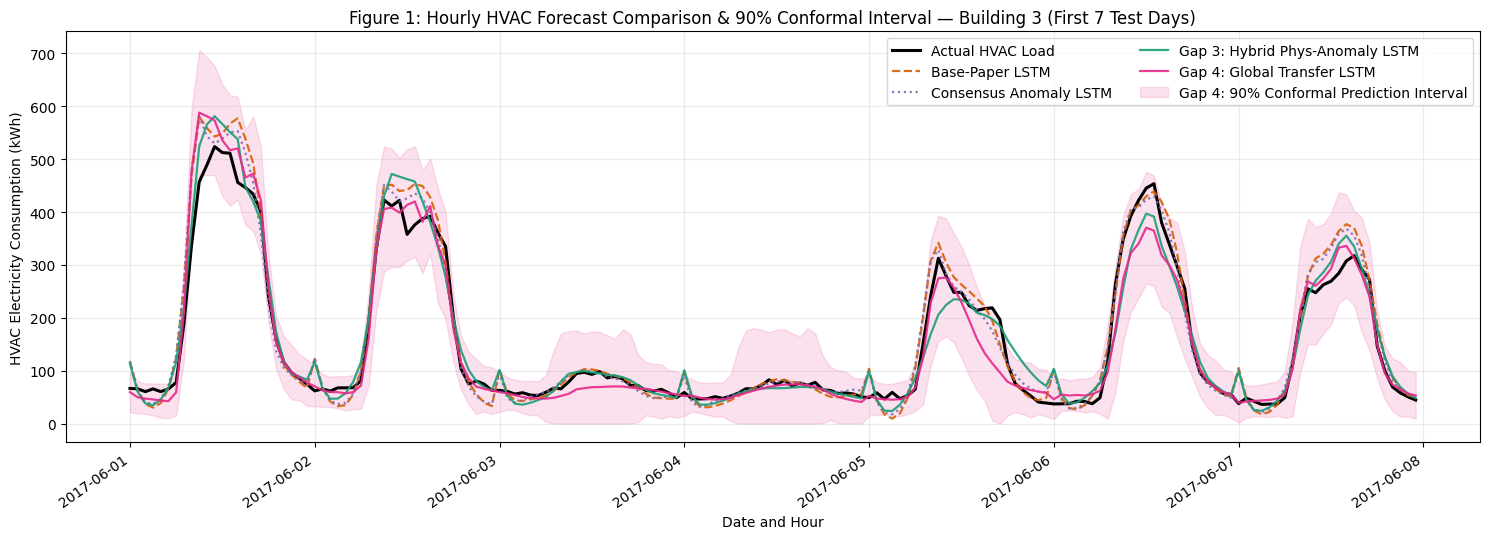

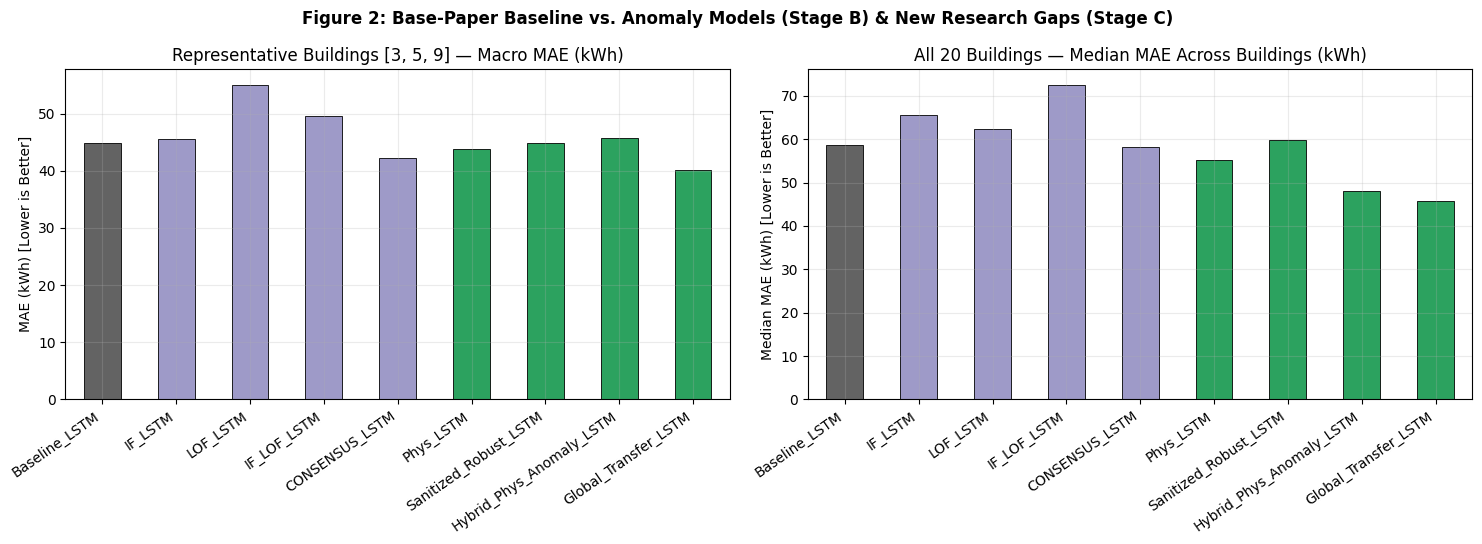

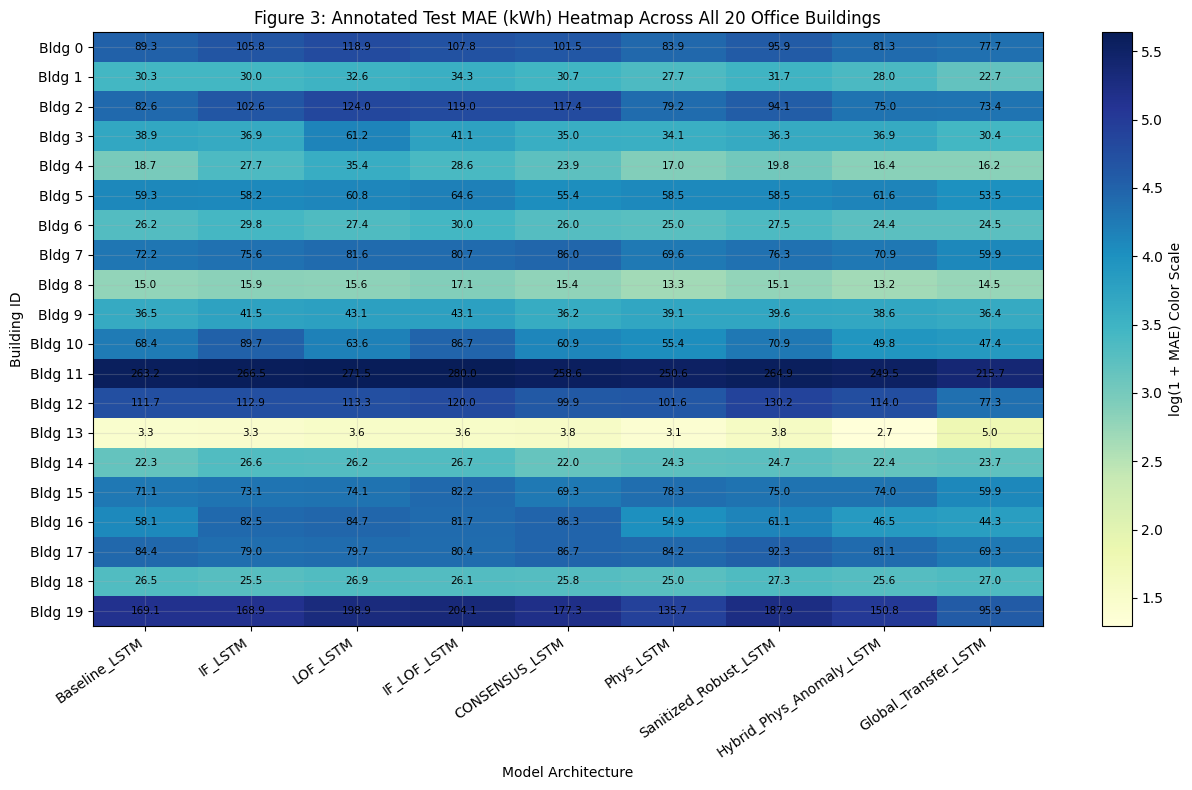

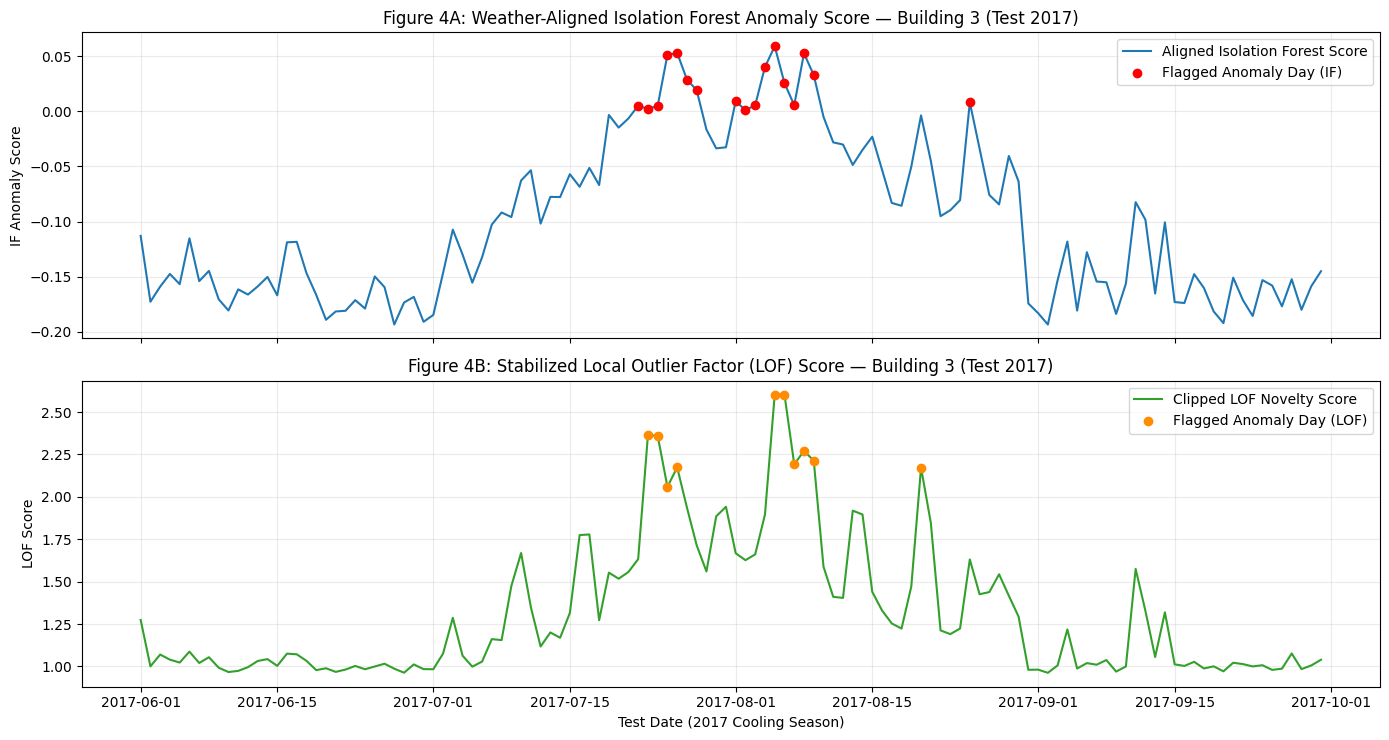

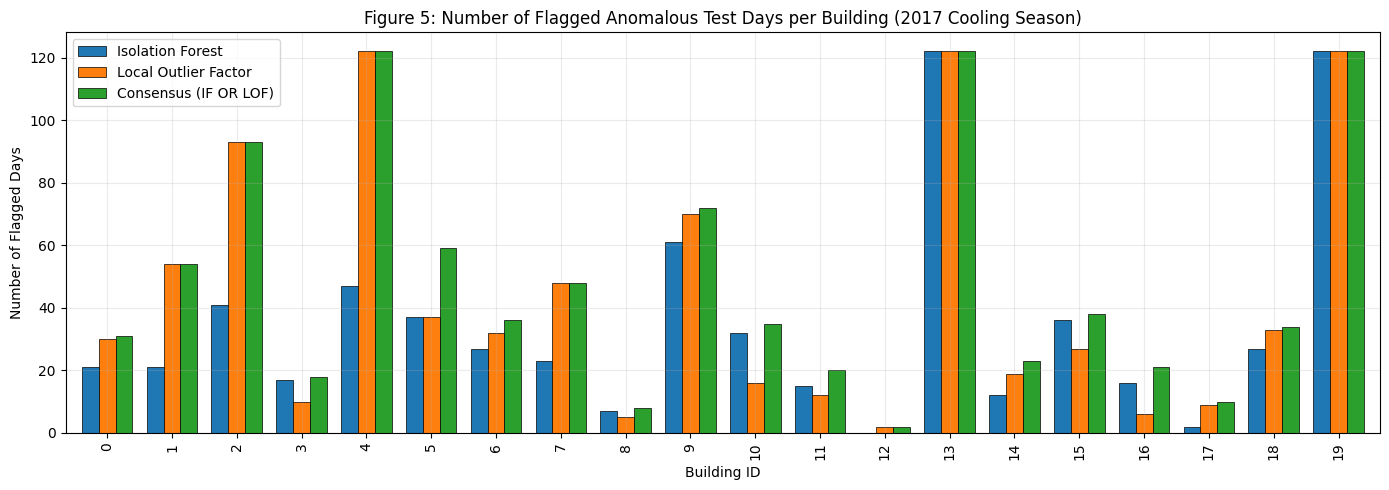

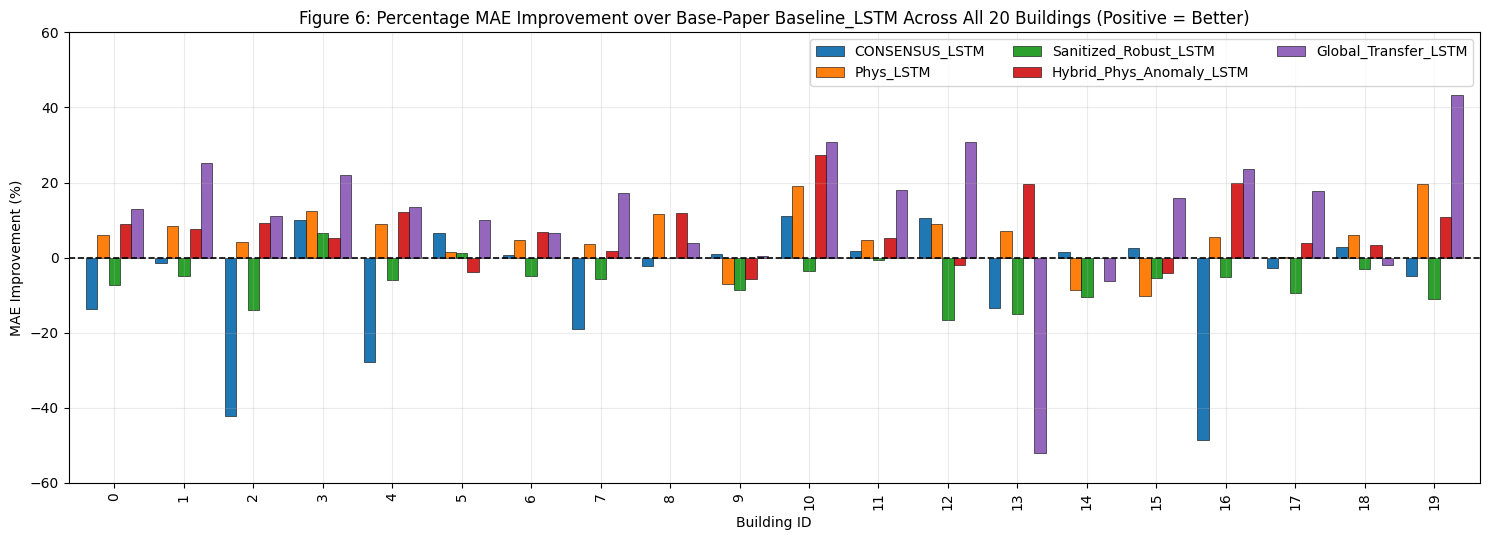

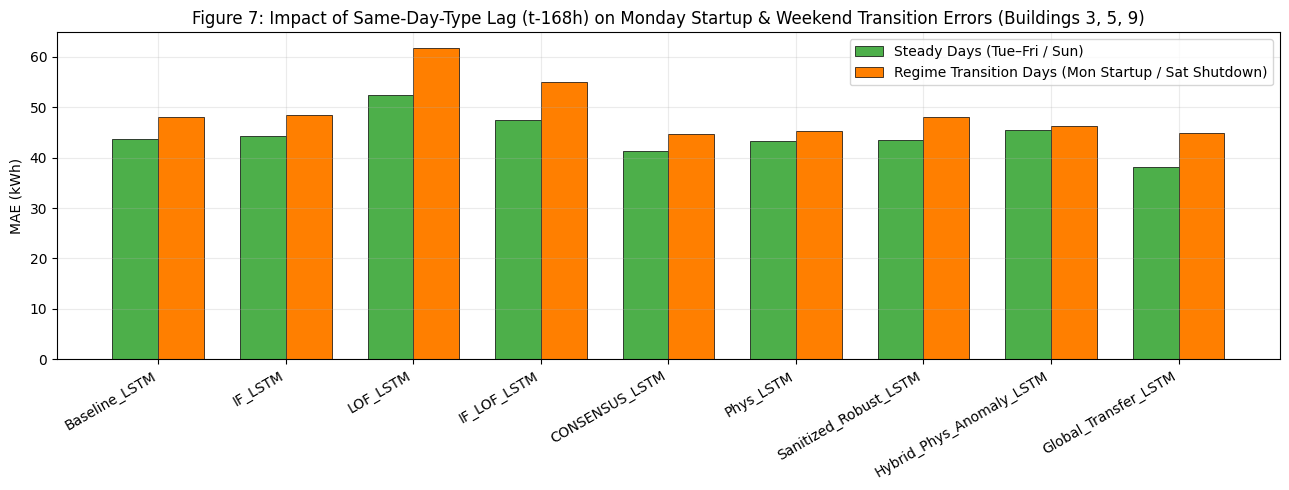

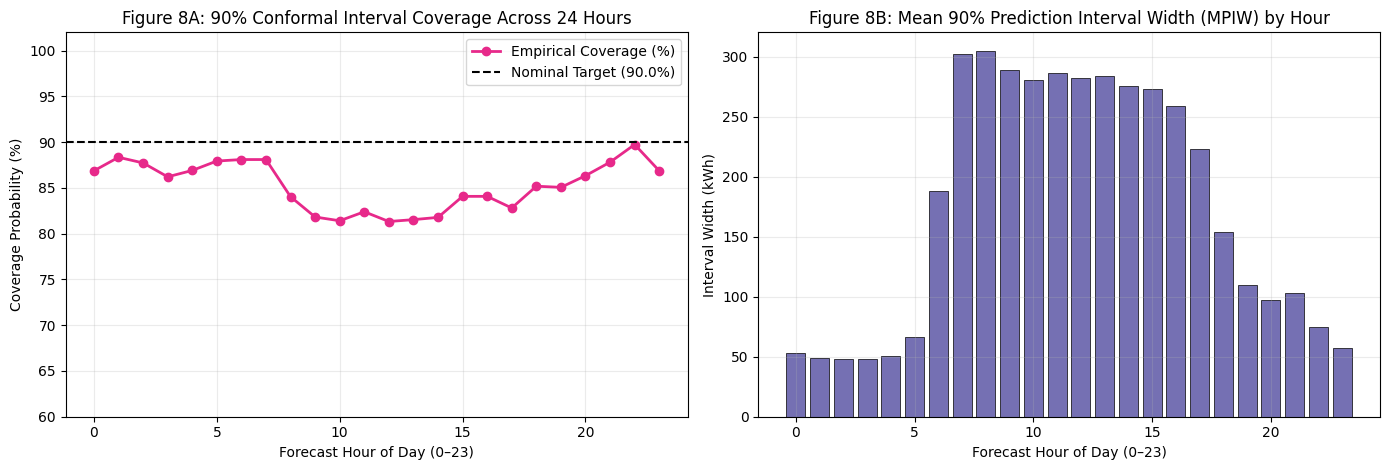

All 8 figures saved successfully to: /content/HVAC_Research_Results


In [23]:
# Ensure OUTPUT_DIR is a Path object even if cell is run standalone
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10
})

building_to_plot = 3

# --------------------------------------------------
# FIGURE 1: ACTUAL VS PREDICTED + 90% CONFORMAL INTERVAL (BUILDING 3)
# --------------------------------------------------
plot_data = all_predictions[all_predictions["building_id"] == building_to_plot].copy()
plot_data["timestamp"] = pd.to_datetime(plot_data["timestamp"])
first_dates = sorted(plot_data["timestamp"].dt.date.unique())[:7]
plot_data = plot_data[plot_data["timestamp"].dt.date.isin(first_dates)]

conf_plot = conformal_df[conformal_df["building_id"] == building_to_plot].copy()
conf_plot["timestamp"] = pd.to_datetime(conf_plot["timestamp"])
conf_plot = conf_plot[conf_plot["timestamp"].dt.date.isin(first_dates)].sort_values("timestamp")

fig, ax = plt.subplots(figsize=(15, 5.5))
actual_line = (
    plot_data[plot_data["model"] == "Baseline_LSTM"]
    .drop_duplicates("timestamp")
    .sort_values("timestamp")
)

ax.plot(actual_line["timestamp"], actual_line["actual"], label="Actual HVAC Load", color="black", linewidth=2.2)

key_models = [
    ("Baseline_LSTM", "Base-Paper LSTM", "--", "#d95f02"),
    ("CONSENSUS_LSTM", "Consensus Anomaly LSTM", ":", "#7570b3"),
    ("Hybrid_Phys_Anomaly_LSTM", "Gap 3: Hybrid Phys-Anomaly LSTM", "-", "#1b9e77"),
    ("Global_Transfer_LSTM", "Gap 4: Global Transfer LSTM", "-", "#e7298a")
]

for m_key, m_label, ls, col in key_models:
    temp = plot_data[plot_data["model"] == m_key].sort_values("timestamp")
    if len(temp) > 0:
        ax.plot(temp["timestamp"], temp["predicted"], label=m_label, linestyle=ls, color=col, linewidth=1.6, alpha=0.9)

if len(conf_plot) > 0:
    ax.fill_between(
        conf_plot["timestamp"],
        conf_plot["lower_90"],
        conf_plot["upper_90"],
        color="#e7298a",
        alpha=0.14,
        label="Gap 4: 90% Conformal Prediction Interval"
    )

ax.set_title("Figure 1: Hourly HVAC Forecast Comparison & 90% Conformal Interval — Building 3 (First 7 Test Days)")
ax.set_xlabel("Date and Hour")
ax.set_ylabel("HVAC Electricity Consumption (kWh)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.legend(loc="upper right", ncol=2, frameon=True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure1_Actual_vs_Predicted_B3.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 2: REPRESENTATIVE VS ALL-20 MEDIAN & MACRO MAE COMPARISON
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

rep_plot = representative_summary.set_index("model").reindex(MODEL_ORDER)["Macro_MAE"]
colors_bar = ["#636363"] + ["#9e9ac8"] * 4 + ["#2ca25f"] * 4
rep_plot.plot(kind="bar", ax=axes[0], color=colors_bar, edgecolor="black", linewidth=0.6)
axes[0].set_title("Representative Buildings [3, 5, 9] — Macro MAE (kWh)")
axes[0].set_ylabel("MAE (kWh) [Lower is Better]")
axes[0].set_xlabel("")
plt.setp(axes[0].get_xticklabels(), rotation=35, ha="right")

all_plot = all20_summary.set_index("model").reindex(MODEL_ORDER)["Median_MAE"]
all_plot.plot(kind="bar", ax=axes[1], color=colors_bar, edgecolor="black", linewidth=0.6)
axes[1].set_title("All 20 Buildings — Median MAE Across Buildings (kWh)")
axes[1].set_ylabel("Median MAE (kWh) [Lower is Better]")
axes[1].set_xlabel("")
plt.setp(axes[1].get_xticklabels(), rotation=35, ha="right")

fig.suptitle("Figure 2: Base-Paper Baseline vs. Anomaly Models (Stage B) & New Research Gaps (Stage C)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure2_Model_MAE_Comparison.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 3: ANNOTATED BUILDING VS MODEL MAE HEATMAP (ALL 20 BUILDINGS)
# --------------------------------------------------
heatmap_data = all20_building_metrics.pivot(index="building_id", columns="model", values="MAE")
heatmap_data = heatmap_data[[m for m in MODEL_ORDER if m in heatmap_data.columns]]

fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(np.log1p(heatmap_data.values), aspect="auto", cmap="YlGnBu")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("log(1 + MAE) Color Scale")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=35, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels([f"Bldg {b}" for b in heatmap_data.index])

for r in range(heatmap_data.shape[0]):
    for c in range(heatmap_data.shape[1]):
        val = heatmap_data.values[r, c]
        ax.text(c, r, f"{val:.1f}", ha="center", va="center", fontsize=7.5, color="black")

ax.set_title("Figure 3: Annotated Test MAE (kWh) Heatmap Across All 20 Office Buildings")
ax.set_xlabel("Model Architecture")
ax.set_ylabel("Building ID")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure3_MAE_Heatmap_All20.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 4: ANOMALY SCORES & INPUT SANITIZATION DIAGNOSTICS (BUILDING 3)
# --------------------------------------------------
anomaly_plot = anomaly_df[anomaly_df["building_id"] == building_to_plot].copy()
anomaly_plot["date"] = pd.to_datetime(anomaly_plot["date"])

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)

axes[0].plot(anomaly_plot["date"], anomaly_plot["IF_score"], color="#1f78b4", label="Aligned Isolation Forest Score")
flagged_if = anomaly_plot[anomaly_plot["IF_flag"] == 1]
axes[0].scatter(flagged_if["date"], flagged_if["IF_score"], color="red", zorder=5, label="Flagged Anomaly Day (IF)")
axes[0].set_title("Figure 4A: Weather-Aligned Isolation Forest Anomaly Score — Building 3 (Test 2017)")
axes[0].set_ylabel("IF Anomaly Score")
axes[0].legend(loc="upper right")

axes[1].plot(anomaly_plot["date"], anomaly_plot["LOF_score"], color="#33a02c", label="Clipped LOF Novelty Score")
flagged_lof = anomaly_plot[anomaly_plot["LOF_flag"] == 1]
axes[1].scatter(flagged_lof["date"], flagged_lof["LOF_score"], color="darkorange", zorder=5, label="Flagged Anomaly Day (LOF)")
axes[1].set_title("Figure 4B: Stabilized Local Outlier Factor (LOF) Score — Building 3 (Test 2017)")
axes[1].set_ylabel("LOF Score")
axes[1].set_xlabel("Test Date (2017 Cooling Season)")
axes[1].legend(loc="upper right")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure4_Anomaly_Scores_B3.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 5: FLAGGED ANOMALY DAYS PER BUILDING (SINGLE CLEAN AXIS)
# --------------------------------------------------
flag_summary = (
    anomaly_df
    .groupby("building_id")[["IF_flag", "LOF_flag", "Consensus_flag"]]
    .sum()
)

fig, ax = plt.subplots(figsize=(14, 5))
flag_summary.plot(kind="bar", ax=ax, width=0.78, edgecolor="black", linewidth=0.5)
ax.set_title("Figure 5: Number of Flagged Anomalous Test Days per Building (2017 Cooling Season)")
ax.set_ylabel("Number of Flagged Days")
ax.set_xlabel("Building ID")
ax.legend(["Isolation Forest", "Local Outlier Factor", "Consensus (IF OR LOF)"])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure5_Anomaly_Counts.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 6: MAE IMPROVEMENT (%) OVER BASELINE LSTM (SELECTED KEY MODELS)
# --------------------------------------------------
selected_imp_models = ["CONSENSUS_LSTM", "Phys_LSTM", "Sanitized_Robust_LSTM", "Hybrid_Phys_Anomaly_LSTM", "Global_Transfer_LSTM"]
imp_pivot = all20_improvement[all20_improvement["model"].isin(selected_imp_models)].pivot(
    index="building_id", columns="model", values="MAE_improvement_percent"
)[selected_imp_models]

fig, ax = plt.subplots(figsize=(15, 5.5))
imp_pivot.plot(kind="bar", ax=ax, width=0.82, edgecolor="black", linewidth=0.4)
ax.axhline(y=0, color="black", linestyle="--", linewidth=1.2)
ax.set_ylim(-60, 60)
ax.set_title("Figure 6: Percentage MAE Improvement over Base-Paper Baseline_LSTM Across All 20 Buildings (Positive = Better)")
ax.set_ylabel("MAE Improvement (%)")
ax.set_xlabel("Building ID")
ax.legend(loc="upper right", ncol=3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure6_MAE_Improvement.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 7: STEADY-DAY VS REGIME-TRANSITION (MONDAY/WEEKEND) MAE
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 5))
x_idx = np.arange(len(regime_df))
w = 0.36
ax.bar(x_idx - w/2, regime_df["Steady_Day_MAE"], width=w, label="Steady Days (Tue–Fri / Sun)", color="#4daf4a", edgecolor="black", linewidth=0.5)
ax.bar(x_idx + w/2, regime_df["Transition_Day_MAE"], width=w, label="Regime Transition Days (Mon Startup / Sat Shutdown)", color="#ff7f00", edgecolor="black", linewidth=0.5)
ax.set_xticks(x_idx)
ax.set_xticklabels(regime_df["model"], rotation=30, ha="right")
ax.set_ylabel("MAE (kWh)")
ax.set_title("Figure 7: Impact of Same-Day-Type Lag (t-168h) on Monday Startup & Weekend Transition Errors (Buildings 3, 5, 9)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure7_Regime_Transition_MAE.png", dpi=300)
plt.show()

# --------------------------------------------------
# FIGURE 8: CONFORMAL PREDICTION INTERVAL COVERAGE BY FORECAST HOUR
# --------------------------------------------------
hourly_cov = conformal_df.groupby("hour").agg(
    empirical_coverage=("covered", lambda s: np.mean(s) * 100.0),
    mean_width=("upper_90", lambda s: np.mean(s.values - conformal_df.loc[s.index, "lower_90"].values))
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(hourly_cov["hour"], hourly_cov["empirical_coverage"], marker="o", color="#e7298a", linewidth=2, label="Empirical Coverage (%)")
axes[0].axhline(90.0, color="black", linestyle="--", label="Nominal Target (90.0%)")
axes[0].set_ylim(60, 102)
axes[0].set_title("Figure 8A: 90% Conformal Interval Coverage Across 24 Hours")
axes[0].set_xlabel("Forecast Hour of Day (0–23)")
axes[0].set_ylabel("Coverage Probability (%)")
axes[0].legend()

axes[1].bar(hourly_cov["hour"], hourly_cov["mean_width"], color="#7570b3", edgecolor="black", linewidth=0.5)
axes[1].set_title("Figure 8B: Mean 90% Prediction Interval Width (MPIW) by Hour")
axes[1].set_xlabel("Forecast Hour of Day (0–23)")
axes[1].set_ylabel("Interval Width (kWh)")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "Figure8_Conformal_Calibration.png", dpi=300)
plt.show()

print("All 8 figures saved successfully to:", OUTPUT_DIR)

## 12. Consolidated results: master comparison, gap-specific tables, statistics, figures 9–15

Everything below is computed from the CSV-backed DataFrames above, for two scopes: **All 20** buildings and the **Clean subset** (meter-quality rule, Section 2b). Statistics: paired Wilcoxon signed-rank vs `Baseline_LSTM` across buildings with **Holm correction**, bootstrap 95 % CI of the mean % MAE improvement, Friedman omnibus test and mean ranks.

In [24]:
try:
    display
except NameError:
    display = print

all_metrics_ext = pd.concat([all_metrics, bench_metrics_df, abl_metrics_df, pooled_metrics_df, gnm_metrics_df], ignore_index=True)
all_predictions_ext = pd.concat([all_predictions, bench_predictions_df, abl_predictions_df, pooled_predictions_df, gnm_predictions_df], ignore_index=True)

def model_group(m):
    if m == "Baseline_LSTM": return "0 Base paper"
    if m.startswith("Naive") or m in ("Ridge_Phys", "Random_Forest_Phys"): return "1 Benchmark"
    if m == "Phys_LSTM" or m.startswith("Base+") or m.startswith("Phys-"): return "2 Gap 1"
    if m.startswith("Pooled") or m.startswith("Global") or m.startswith("ZeroShot"): return "3 Gap 2"
    return "4 Appendix: anomaly"

def holm_adjust(p):
    p = np.asarray(p, dtype=float); out = np.full(len(p), np.nan)
    valid = np.where(~np.isnan(p))[0]; order = valid[np.argsort(p[valid])]; m = len(valid); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); out[i] = min(1.0, run)
    return out

def bootstrap_ci(x, n_boot=5000, seed=0):
    x = np.asarray(x, dtype=float); rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def master_table(metrics, building_ids, baseline="Baseline_LSTM", min_buildings=3):
    sub = metrics[metrics["building_id"].isin(building_ids)]
    pb = sub.groupby(["model", "building_id"])[["MAE", "RMSE", "CVRMSE", "NMBE", "R2", "training_seconds"]].mean().reset_index()
    piv = pb.pivot(index="building_id", columns="model", values="MAE")
    rows = []
    for m in piv.columns:
        common = piv[[baseline, m]].dropna().index
        if len(common) < min_buildings:
            continue
        b = piv.loc[common, baseline].values; v = piv.loc[common, m].values
        imp = (b - v) / np.maximum(b, 1e-8) * 100.0
        if m == baseline:
            p, lo, hi = np.nan, np.nan, np.nan
        else:
            try: p = stats.wilcoxon(b, v).pvalue
            except Exception: p = np.nan
            lo, hi = bootstrap_ci(imp)
        d = pb[(pb["model"] == m) & (pb["building_id"].isin(common))]
        rows.append({"model": m, "group": model_group(m), "n_buildings": len(common),
                     "MAE_mean": v.mean(), "MAE_median": np.median(v),
                     "CVRMSE_median": d["CVRMSE"].median(), "NMBE_median": d["NMBE"].median(), "R2_median": d["R2"].median(),
                     "MAE_imp_mean_%": imp.mean(), "MAE_imp_median_%": np.median(imp), "CI95_lo": lo, "CI95_hi": hi,
                     "buildings_improved": f"{int((imp > 0).sum())}/{len(imp)}", "p_wilcoxon": p,
                     "train_sec_mean": d["training_seconds"].mean()})
    df = pd.DataFrame(rows)
    df["p_holm"] = holm_adjust(df["p_wilcoxon"].values)
    df["significant_holm_0.05"] = df["p_holm"] < 0.05
    return df.sort_values(["group", "MAE_imp_median_%"], ascending=[True, False]).reset_index(drop=True)

master_all20 = master_table(all_metrics_ext, ALL_BUILDINGS)
master_clean = master_table(all_metrics_ext, CLEAN_BUILDINGS)
master_all20.to_csv(OUTPUT_DIR / "Master_Table_All20.csv", index=False)
master_clean.to_csv(OUTPUT_DIR / "Master_Table_CleanSubset.csv", index=False)

cols_show = ["model", "group", "n_buildings", "MAE_median", "CVRMSE_median", "MAE_imp_mean_%", "MAE_imp_median_%", "CI95_lo", "CI95_hi",
             "buildings_improved", "p_wilcoxon", "p_holm", "train_sec_mean"]
print(f"=== TABLE 5: MASTER COMPARISON — CLEAN SUBSET ({len(CLEAN_BUILDINGS)} buildings; excluded {EXCLUDED_BUILDINGS}) ===")
display(master_clean[cols_show].round(4))
print("\n=== TABLE 6: MASTER COMPARISON — ALL 20 BUILDINGS ===")
display(master_all20[cols_show].round(4))

# ---------- Friedman omnibus + mean ranks on core models ----------
core = ["Baseline_LSTM", "Naive_t-168h", "Ridge_Phys", "Random_Forest_Phys", "Phys_LSTM", "Global_Transfer_LSTM"]
pb_clean = all_metrics_ext[all_metrics_ext["building_id"].isin(CLEAN_BUILDINGS)].groupby(["model", "building_id"])["MAE"].mean().unstack("model")
pb_core = pb_clean[core].dropna()
fr_stat, fr_p = stats.friedmanchisquare(*[pb_core[c].values for c in core])
mean_ranks = pb_core.rank(axis=1).mean().sort_values()
print(f"\n=== TABLE 7: FRIEDMAN TEST (clean subset, n={len(pb_core)} buildings): chi2={fr_stat:.2f}, p={fr_p:.4g} ===")
display(mean_ranks.round(2).to_frame("mean_rank (1 = best)"))
mean_ranks.to_csv(OUTPUT_DIR / "Friedman_Mean_Ranks.csv")

# ---------- Gap-specific tables ----------
gap1_models = ["Baseline_LSTM", "Naive_t-168h", "Base+WeatherExtra", "Base+Psychrometric", "Base+Lag168h", "Base+Context", "Base+Cyclic", "Base+ResidScore", "Phys_LSTM"] \
              + sorted([m for m in master_clean["model"] if m.startswith("Phys-")])
gap2_models = ["Baseline_LSTM", "Phys_LSTM", "Pooled_Base_LSTM", "Pooled_Phys_LSTM", "Global_NoMeta_LSTM", "Global_Transfer_LSTM", "ZeroShot_Pooled_Phys_LSTM"]

def sub_table(master, models, name):
    t = master[master["model"].isin(models)].set_index("model").reindex([m for m in models if m in set(master["model"])]).reset_index()
    t.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    return t

T_gap1 = sub_table(master_clean, gap1_models, "Table_Gap1_FeatureAblation_Clean")
T_gap2 = sub_table(master_clean, gap2_models, "Table_Gap2_Transfer_Clean")
print("\n=== TABLE 8 (Gap 1): FEATURE-GROUP ABLATION vs BASE PAPER (clean subset, extra-experiment buildings) ===")
display(T_gap1[["model", "n_buildings", "MAE_median", "MAE_imp_mean_%", "CI95_lo", "CI95_hi", "buildings_improved", "p_wilcoxon", "p_holm"]].round(4))
print("\n=== TABLE 9 (Gap 2): POOLING vs METADATA vs ZERO-SHOT (clean subset) ===")
display(T_gap2[["model", "n_buildings", "MAE_median", "MAE_imp_mean_%", "CI95_lo", "CI95_hi", "buildings_improved", "p_wilcoxon", "p_holm", "train_sec_mean"]].round(4))

# Monday / transition analysis for Gap 1 (normalised by building mean so large buildings do not dominate)
pred_c = all_predictions_ext[all_predictions_ext["building_id"].isin(CLEAN_BUILDINGS) & all_predictions_ext["model"].isin(
    ["Baseline_LSTM", "Naive_t-168h", "Base+Lag168h", "Phys_LSTM", "Global_Transfer_LSTM"])].copy()
pred_c["timestamp"] = pd.to_datetime(pred_c["timestamp"])
pred_c["abs_err"] = (pred_c["actual"] - pred_c["predicted"]).abs()
bmean = pred_c.groupby("building_id")["actual"].transform("mean")
pred_c["nabs_err_%"] = pred_c["abs_err"] / bmean * 100.0
regime_norm = pred_c.groupby(["model", "regime_shift"])["nabs_err_%"].mean().unstack("regime_shift").rename(columns={0: "steady_days_nMAE_%", 1: "transition_days_nMAE_%"})
print("\n=== TABLE 10 (Gap 1): NORMALISED ERROR ON STEADY vs TRANSITION DAYS (clean subset) ===")
display(regime_norm.round(2)); regime_norm.to_csv(OUTPUT_DIR / "Table_Gap1_Regime_Normalised.csv")

# ---------- Gap 3 tables ----------
rob_c = rob_df[rob_df["building_id"].isin(CLEAN_BUILDINGS)].groupby(["arm", "sigma", "building_id"])["MAE"].mean().reset_index()
rob_med = rob_c.groupby(["arm", "sigma"])["MAE"].median().unstack("sigma")
rob_deg = rob_med.div(rob_med[0], axis=0).sub(1).mul(100)
naive168_med = bench_metrics_df[bench_metrics_df["building_id"].isin(set(rob_c["building_id"]))].groupby("building_id")["MAE"].mean()
naive168_med = bench_metrics_df[(bench_metrics_df["model"] == "Naive_t-168h") & bench_metrics_df["building_id"].isin(set(rob_c["building_id"]))].groupby("building_id")["MAE"].mean().median()
print(f"\n=== TABLE 11 (Gap 3a): MEDIAN MAE vs WEATHER-FORECAST ERROR σ (°C) — clean subset; naive t-168h median MAE = {naive168_med:.2f} ===")
display(rob_med.round(2))
print("\n   Relative degradation vs σ=0 (%):"); display(rob_deg.round(1))
rob_med.to_csv(OUTPUT_DIR / "Table_Gap3_Robustness_MAE.csv"); rob_deg.to_csv(OUTPUT_DIR / "Table_Gap3_Robustness_Degradation.csv")

if "NoWeather_LSTM" in rob_med.index:
    for arm in ["Baseline_LSTM", "Phys_LSTM", "Phys_NoiseAug_LSTM"]:
        worse = [s for s in rob_med.columns if rob_med.loc[arm, s] > rob_med.loc["NoWeather_LSTM", s]]
        print(f"  {arm}: first σ where it is worse than NoWeather_LSTM -> {worse[0] if worse else 'none in tested range'}")

conf_c = conf_df[conf_df["building_id"].isin(CLEAN_BUILDINGS)]
conf_0 = conf_c[(conf_c["sigma"] == 0)].groupby(["arm", "calibration", "level"])[["PICP", "MPIW"]].mean().round(2)
conf_noise = conf_c[(conf_c["level"] == 0.90)].groupby(["arm", "calibration", "sigma"])[["PICP", "MPIW"]].mean().round(2)
print("\n=== TABLE 12 (Gap 3b): INTERVAL RELIABILITY AT σ=0 (nominal 80/90/95 %) ===")
display(conf_0.unstack("level"))
print("\n=== TABLE 13 (Gap 3b): 90 % INTERVAL COVERAGE (PICP) / WIDTH (MPIW) vs σ ===")
display(conf_noise)
conf_0.to_csv(OUTPUT_DIR / "Table_Gap3_Conformal_sigma0.csv"); conf_noise.to_csv(OUTPUT_DIR / "Table_Gap3_Conformal_vs_sigma.csv")

=== TABLE 5: MASTER COMPARISON — CLEAN SUBSET (18 buildings; excluded [11, 19]) ===


,model,group,n_buildings,MAE_median,CVRMSE_median,MAE_imp_mean_%,MAE_imp_median_%,CI95_lo,CI95_hi,buildings_improved,p_wilcoxon,p_holm,train_sec_mean
0,Baseline_LSTM,0 Base paper,18,48.4954,31.3725,0.0000,0.0000,NaN,NaN,0/18,NaN,NaN,7.8075
1,Random_Forest_Phys,1 Benchmark,18,45.9258,40.5814,-5.7904,-1.3123,-17.4844,3.5731,9/18,0.6397,1.0000,0.9693
2,Naive_t-168h,1 Benchmark,18,56.9298,47.0541,-15.1565,-9.9771,-34.5927,3.6437,6/18,0.0814,0.9771,0.0000
3,Ridge_Phys,1 Benchmark,18,55.0160,42.1711,-12.9453,-10.0183,-19.6179,-6.7339,3/18,0.0019,0.0347,0.3677
4,Naive_t-24h,1 Benchmark,18,81.3589,77.0652,-73.0956,-68.7622,-98.0852,-47.6581,2/18,0.0000,0.0008,0.0000
5,Base+Lag168h,2 Gap 1,8,42.4763,22.4092,9.1191,8.6738,4.6713,13.5191,7/8,0.0234,0.3516,7.4710
6,Phys_LSTM,2 Gap 1,18,47.0104,29.1707,4.5593,5.6951,1.0842,7.8348,15/18,0.0237,0.3516,7.1356
7,Base+Context,2 Gap 1,8,46.0709,22.8338,1.7465,3.5129,-2.9592,5.7732,6/8,0.7422,1.0000,8.4456
8,Base+Cyclic,2 Gap 1,8,47.3127,21.9364,2.1595,3.3113,-1.7846,5.3369,6/8,0.2500,1.0000,7.9940
9,Base+ResidScore,2 Gap 1,8,46.7126,23.0520,1.4472,2.3804,-3.3127,5.3235,6/8,0.3125,1.0000,8.3508



=== TABLE 6: MASTER COMPARISON — ALL 20 BUILDINGS ===


,model,group,n_buildings,MAE_median,CVRMSE_median,MAE_imp_mean_%,MAE_imp_median_%,CI95_lo,CI95_hi,buildings_improved,p_wilcoxon,p_holm,train_sec_mean
0,Baseline_LSTM,0 Base paper,20,58.7134,35.5283,0.0000,0.0000,NaN,NaN,0/20,NaN,NaN,7.4344
1,Random_Forest_Phys,1 Benchmark,20,46.7744,41.0524,-5.1032,-0.1945,-15.4733,3.2956,10/20,0.7841,1.0000,0.9738
2,Naive_t-168h,1 Benchmark,20,56.9298,47.0541,-9.8478,-9.9771,-29.9367,11.3740,7/20,0.1429,1.0000,0.0000
3,Ridge_Phys,1 Benchmark,20,65.9957,44.4380,-12.1753,-10.0183,-18.3822,-6.5479,4/20,0.0027,0.0461,0.3693
4,Naive_t-24h,1 Benchmark,20,81.3589,77.0652,-61.8604,-54.2415,-88.9642,-32.0661,3/20,0.0012,0.0218,0.0000
5,Base+Lag168h,2 Gap 1,8,42.4763,22.4092,9.1191,8.6738,4.6713,13.5191,7/8,0.0234,0.3047,7.4710
6,Phys_LSTM,2 Gap 1,20,55.1494,34.1667,5.3298,5.6951,2.1000,8.5746,17/20,0.0064,0.1022,6.9717
7,Base+Context,2 Gap 1,8,46.0709,22.8338,1.7465,3.5129,-2.9592,5.7732,6/8,0.7422,1.0000,8.4456
8,Base+Cyclic,2 Gap 1,8,47.3127,21.9364,2.1595,3.3113,-1.7846,5.3369,6/8,0.2500,1.0000,7.9940
9,Base+ResidScore,2 Gap 1,8,46.7126,23.0520,1.4472,2.3804,-3.3127,5.3235,6/8,0.3125,1.0000,8.3508



=== TABLE 7: FRIEDMAN TEST (clean subset, n=18 buildings): chi2=36.48, p=7.627e-07 ===


,mean_rank (1 = best)
model,
Global_Transfer_LSTM,1.78
Phys_LSTM,2.50
Random_Forest_Phys,3.61
Baseline_LSTM,3.67
Naive_t-168h,4.50
Ridge_Phys,4.94


... (10 outputs left out)

  Baseline_LSTM: first σ where it is worse than NoWeather_LSTM -> 4
  Phys_LSTM: first σ where it is worse than NoWeather_LSTM -> 4
  Phys_NoiseAug_LSTM: first σ where it is worse than NoWeather_LSTM -> none in tested range

=== TABLE 12 (Gap 3b): INTERVAL RELIABILITY AT σ=0 (nominal 80/90/95 %) ===


PICP                  MPIW                
level                              0.80   0.90   0.95    0.80    0.90    0.95
arm                calibration                                               
Baseline_LSTM      noise_matched  79.41  88.48  93.41  152.28  198.99  244.79
                   rolling_28d    77.14  85.88  90.90  144.01  178.20  205.60
                   static_clean   79.41  88.48  93.41  152.28  198.99  244.79
NoWeather_LSTM     noise_matched  79.61  89.22  94.27  188.14  259.91  335.79
                   rolling_28d    77.28  86.59  91.54  170.33  225.82  271.61
                   static_clean   79.61  89.22  94.27  188.14  259.91  335.79
Phys_LSTM          noise_matched  78.56  88.13  93.20  142.84  189.60  231.53
                   rolling_28d    76.95  86.24  91.11  137.72  170.54  198.42
                   static_clean   78.56  88.13  93.20  142.84  189.60  231.53
Phys_NoiseAug_LSTM noise_matched  78.16  87.43  92.94  142.62  189.72  234.78
                   rolling_28d    77.27  86.39  91.41  136.25  172.31  201.79
                   static_clean   78.16  87.43  92.94  142.62  189.72  234.78


=== TABLE 13 (Gap 3b): 90 % INTERVAL COVERAGE (PICP) / WIDTH (MPIW) vs σ ===


PICP    MPIW
arm                calibration   sigma               
Baseline_LSTM      noise_matched 0      88.48  198.99
                                 2      89.60  233.52
                                 4      90.12  296.98
                   rolling_28d   0      85.88  178.20
                                 2      86.62  212.86
                                 4      86.97  275.02
                   static_clean  0      88.48  198.99
                                 2      84.18  198.80
                                 4      76.23  198.25
NoWeather_LSTM     noise_matched 0      89.22  259.91
                                 2      89.22  259.91
                                 4      89.22  259.91
                   rolling_28d   0      86.59  225.82
                                 2      86.59  225.82
                                 4      86.59  225.82
                   static_clean  0      89.22  259.91
                                 2      89.22  259.91
                                 4      89.22  259.91
Phys_LSTM          noise_matched 0      88.13  189.60
                                 2      89.05  211.07
                                 4      90.09  263.22
                   rolling_28d   0      86.24  170.54
                                 2      86.52  193.41
                                 4      86.74  242.56
                   static_clean  0      88.13  189.60
                                 2      84.99  189.62
                                 4      78.71  189.51
Phys_NoiseAug_LSTM noise_matched 0      87.43  189.72
                                 2      87.81  197.04
                                 4      88.75  219.39
                   rolling_28d   0      86.39  172.31
                                 2      86.58  180.80
                                 4      86.80  199.29
                   static_clean  0      87.43  189.72
                                 2      86.33  189.72
                                 4      84.12  189.59

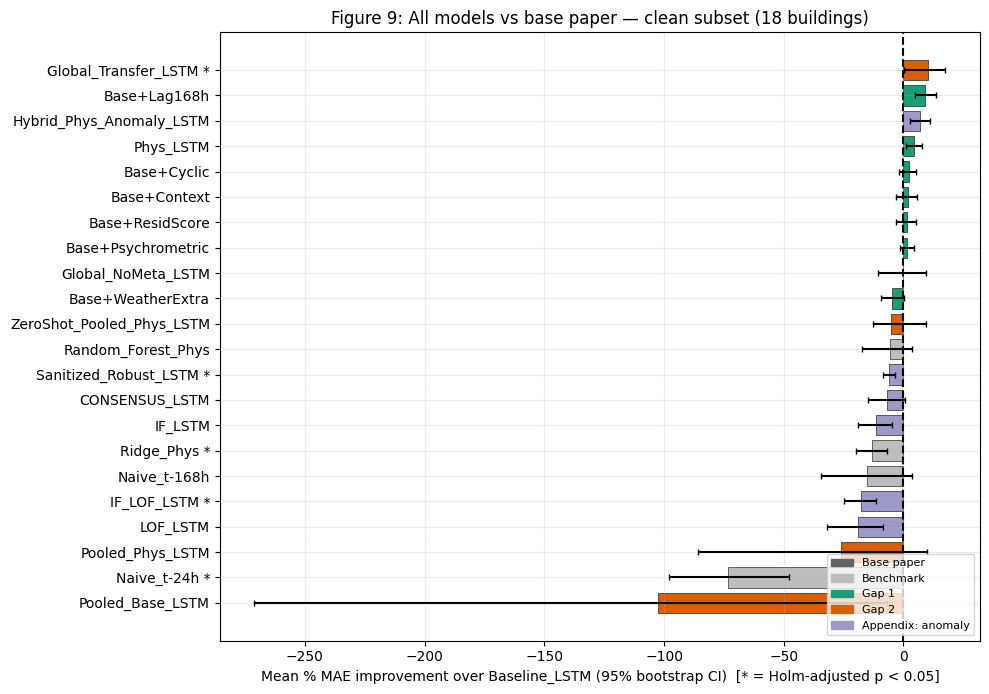

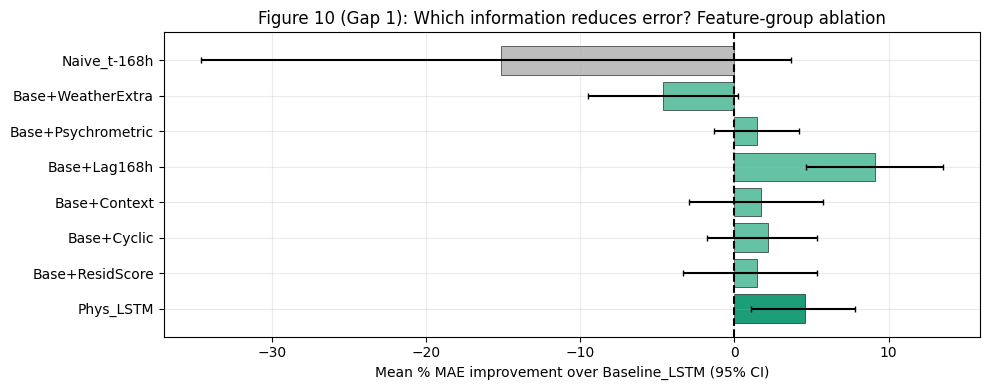

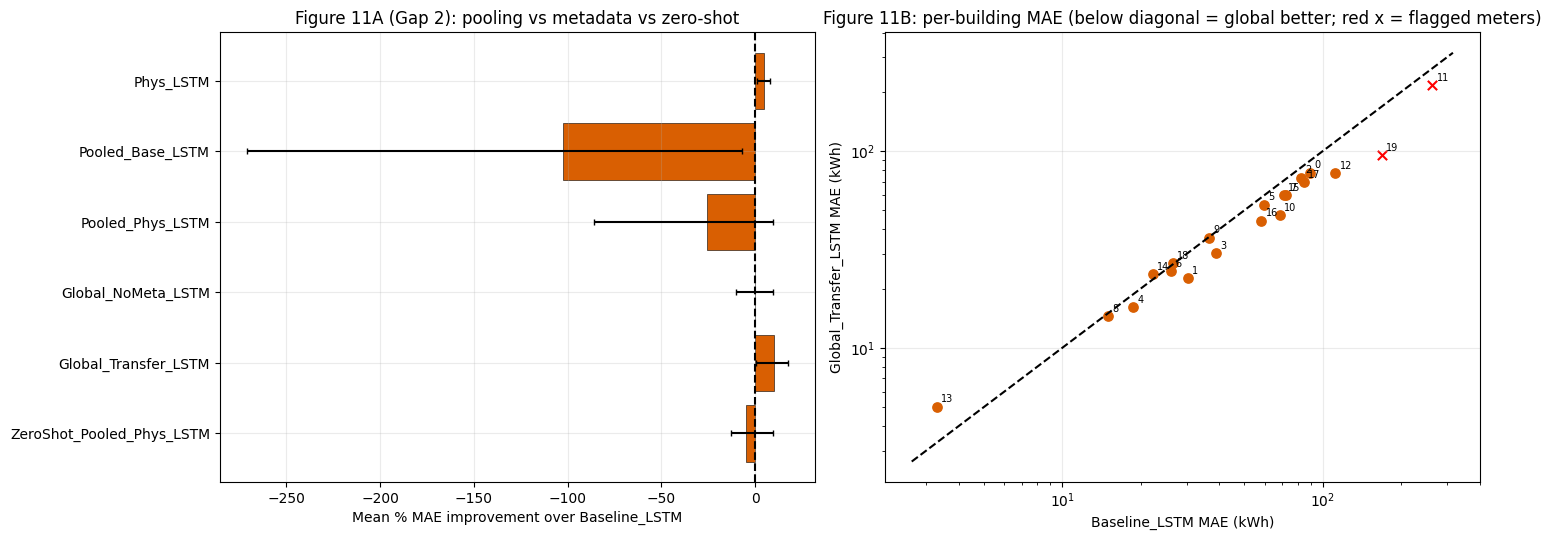

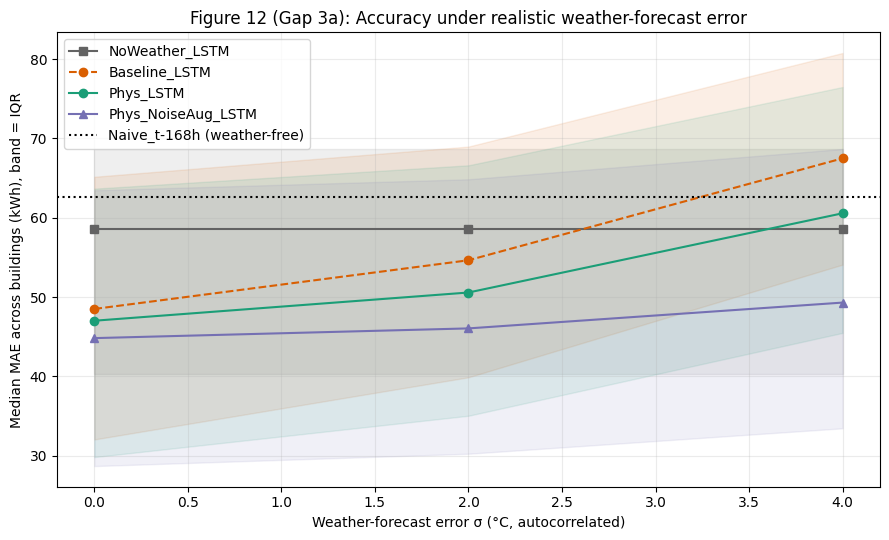

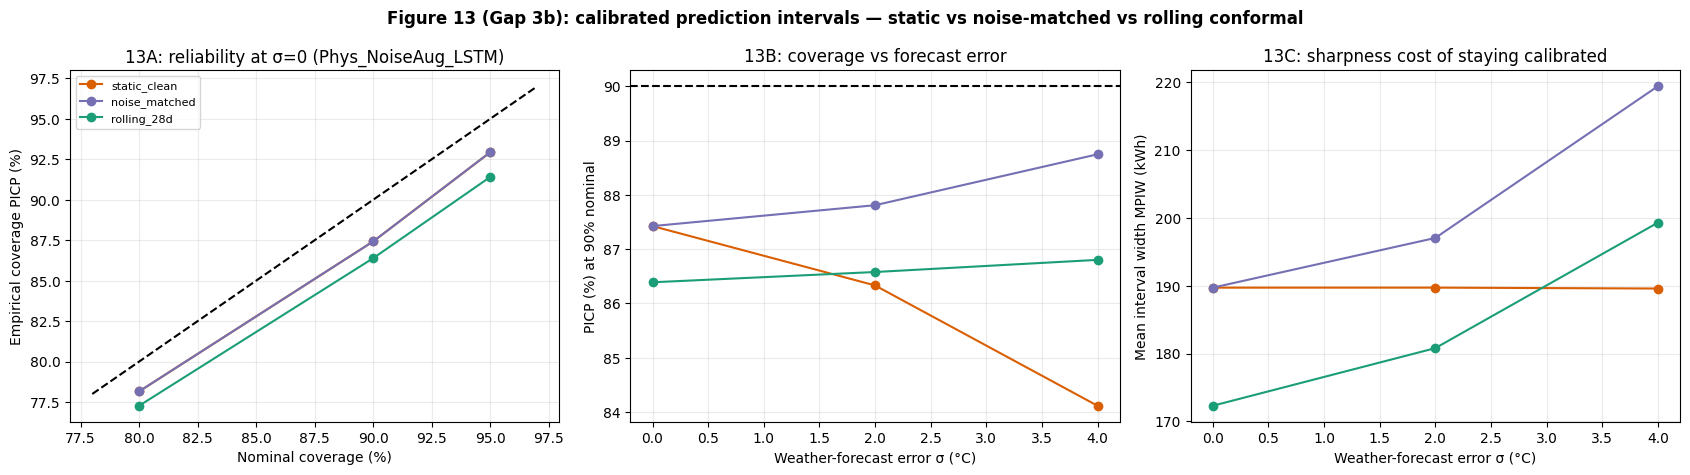

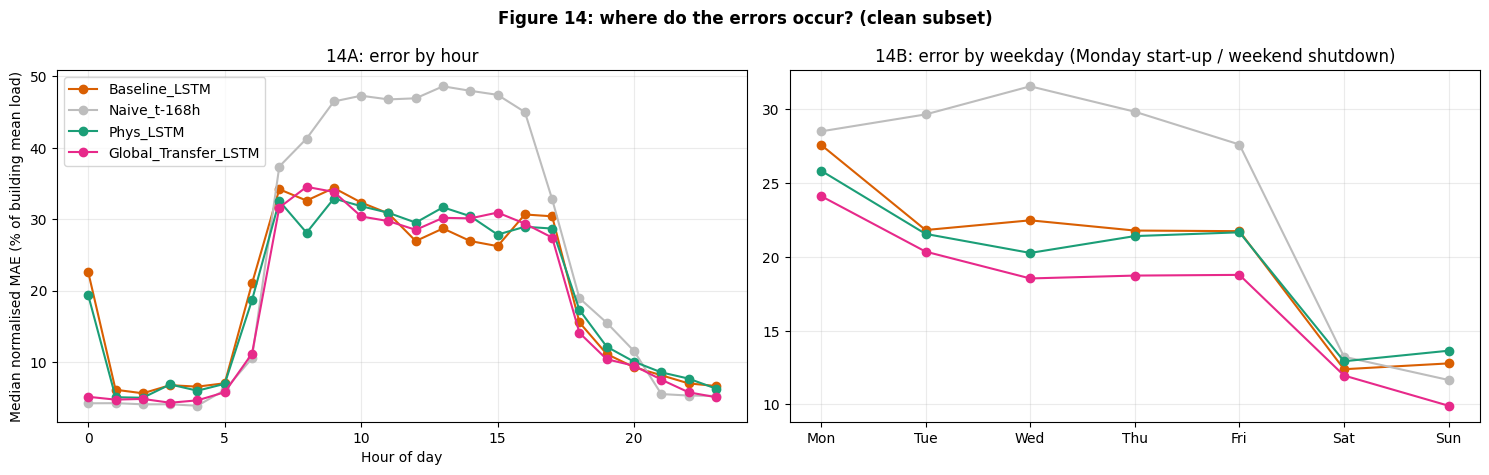

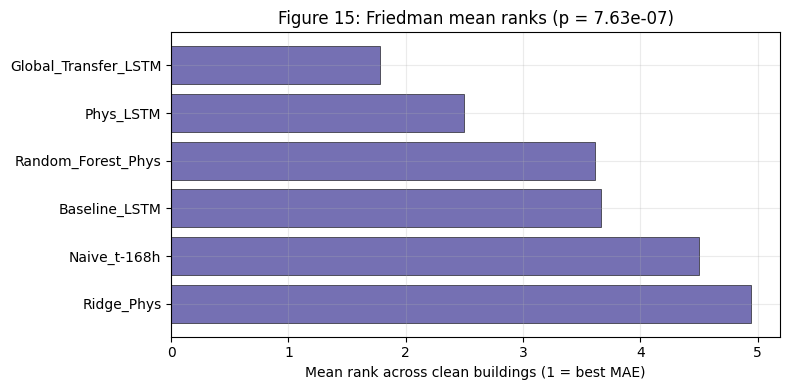

In [25]:
plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
GROUP_COLORS = {"0 Base paper": "#636363", "1 Benchmark": "#bdbdbd", "2 Gap 1": "#1b9e77", "3 Gap 2": "#d95f02", "4 Appendix: anomaly": "#9e9ac8"}

# ---------- FIGURE 9: master forest plot ----------
fm = master_clean[master_clean["model"] != "Baseline_LSTM"].sort_values("MAE_imp_mean_%").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, max(5, 0.32 * len(fm))))
ypos = np.arange(len(fm))
ax.barh(ypos, fm["MAE_imp_mean_%"], color=[GROUP_COLORS[g] for g in fm["group"]], edgecolor="black", linewidth=0.4)
ax.errorbar(fm["MAE_imp_mean_%"], ypos, xerr=[fm["MAE_imp_mean_%"] - fm["CI95_lo"], fm["CI95_hi"] - fm["MAE_imp_mean_%"]], fmt="none", ecolor="black", capsize=2)
ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(ypos); ax.set_yticklabels([f"{m}{' *' if s else ''}" for m, s in zip(fm["model"], fm["significant_holm_0.05"])])
ax.set_xlabel("Mean % MAE improvement over Baseline_LSTM (95% bootstrap CI)  [* = Holm-adjusted p < 0.05]")
ax.set_title(f"Figure 9: All models vs base paper — clean subset ({len(CLEAN_BUILDINGS)} buildings)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, [g[2:] for g in GROUP_COLORS], loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure9_Master_Forest.png", dpi=300); plt.show()

# ---------- FIGURE 10: Gap 1 feature ablation ----------
g1 = T_gap1[T_gap1["model"] != "Baseline_LSTM"].copy()
fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(g1))))
ypos = np.arange(len(g1))
colors = ["#bdbdbd" if m.startswith("Naive") else ("#1b9e77" if m == "Phys_LSTM" else "#66c2a5") for m in g1["model"]]
ax.barh(ypos, g1["MAE_imp_mean_%"], color=colors, edgecolor="black", linewidth=0.4)
ax.errorbar(g1["MAE_imp_mean_%"], ypos, xerr=[g1["MAE_imp_mean_%"] - g1["CI95_lo"], g1["CI95_hi"] - g1["MAE_imp_mean_%"]], fmt="none", ecolor="black", capsize=2)
ax.axvline(0, color="black", linestyle="--"); ax.set_yticks(ypos); ax.set_yticklabels(g1["model"]); ax.invert_yaxis()
ax.set_xlabel("Mean % MAE improvement over Baseline_LSTM (95% CI)")
ax.set_title("Figure 10 (Gap 1): Which information reduces error? Feature-group ablation")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure10_Gap1_Ablation.png", dpi=300); plt.show()

# ---------- FIGURE 11: Gap 2 ----------
g2 = T_gap2[T_gap2["model"] != "Baseline_LSTM"].copy()
pb_all = all_metrics_ext.groupby(["model", "building_id"])["MAE"].mean().unstack("model")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ypos = np.arange(len(g2))
axes[0].barh(ypos, g2["MAE_imp_mean_%"], color="#d95f02", edgecolor="black", linewidth=0.4)
axes[0].errorbar(g2["MAE_imp_mean_%"], ypos, xerr=[(g2["MAE_imp_mean_%"] - g2["CI95_lo"]).fillna(0), (g2["CI95_hi"] - g2["MAE_imp_mean_%"]).fillna(0)], fmt="none", ecolor="black", capsize=2)
axes[0].axvline(0, color="black", linestyle="--"); axes[0].set_yticks(ypos); axes[0].set_yticklabels(g2["model"]); axes[0].invert_yaxis()
axes[0].set_xlabel("Mean % MAE improvement over Baseline_LSTM"); axes[0].set_title("Figure 11A (Gap 2): pooling vs metadata vs zero-shot")
if "Global_Transfer_LSTM" in pb_all.columns:
    for b in pb_all.index:
        flagged = b in EXCLUDED_BUILDINGS
        axes[1].scatter(pb_all.loc[b, "Baseline_LSTM"], pb_all.loc[b, "Global_Transfer_LSTM"], c="red" if flagged else "#d95f02", marker="x" if flagged else "o", s=45)
        axes[1].annotate(str(b), (pb_all.loc[b, "Baseline_LSTM"], pb_all.loc[b, "Global_Transfer_LSTM"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    lim = [pb_all[["Baseline_LSTM", "Global_Transfer_LSTM"]].min().min() * 0.8, pb_all[["Baseline_LSTM", "Global_Transfer_LSTM"]].max().max() * 1.2]
    axes[1].plot(lim, lim, "k--"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
    axes[1].set_xlabel("Baseline_LSTM MAE (kWh)"); axes[1].set_ylabel("Global_Transfer_LSTM MAE (kWh)")
    axes[1].set_title("Figure 11B: per-building MAE (below diagonal = global better; red x = flagged meters)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure11_Gap2_Transfer.png", dpi=300); plt.show()

# ---------- FIGURE 12: Gap 3a robustness ----------
fig, ax = plt.subplots(figsize=(9, 5.5))
styles = {"NoWeather_LSTM": ("#636363", "s", "-"), "Baseline_LSTM": ("#d95f02", "o", "--"), "Phys_LSTM": ("#1b9e77", "o", "-"), "Phys_NoiseAug_LSTM": ("#7570b3", "^", "-")}
for arm, (col, mk, ls) in styles.items():
    if arm not in rob_c["arm"].unique():
        continue
    d = rob_c[rob_c["arm"] == arm].groupby("sigma")["MAE"]
    med, q1, q3 = d.median(), d.quantile(0.25), d.quantile(0.75)
    ax.plot(med.index, med.values, color=col, marker=mk, linestyle=ls, label=arm)
    ax.fill_between(med.index, q1.values, q3.values, color=col, alpha=0.10)
ax.axhline(naive168_med, color="black", linestyle=":", label="Naive_t-168h (weather-free)")
ax.set_xlabel("Weather-forecast error σ (°C, autocorrelated)"); ax.set_ylabel("Median MAE across buildings (kWh), band = IQR")
ax.set_title("Figure 12 (Gap 3a): Accuracy under realistic weather-forecast error"); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure12_Gap3_Weather_Noise.png", dpi=300); plt.show()

# ---------- FIGURE 13: Gap 3b intervals ----------
cal_colors = {"static_clean": "#d95f02", "noise_matched": "#7570b3", "rolling_28d": "#1b9e77"}
arm_plot = "Phys_NoiseAug_LSTM" if "Phys_NoiseAug_LSTM" in conf_c["arm"].unique() else "Phys_LSTM"
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for cal, col in cal_colors.items():
    d0 = conf_c[(conf_c["arm"] == arm_plot) & (conf_c["calibration"] == cal) & (conf_c["sigma"] == 0)].groupby("level")["PICP"].mean()
    axes[0].plot(d0.index * 100, d0.values, marker="o", color=col, label=cal)
    d1 = conf_c[(conf_c["arm"] == arm_plot) & (conf_c["calibration"] == cal) & (conf_c["level"] == 0.90)].groupby("sigma")[["PICP", "MPIW"]].mean()
    axes[1].plot(d1.index, d1["PICP"], marker="o", color=col, label=cal); axes[2].plot(d1.index, d1["MPIW"], marker="o", color=col, label=cal)
axes[0].plot([78, 97], [78, 97], "k--"); axes[0].set_xlabel("Nominal coverage (%)"); axes[0].set_ylabel("Empirical coverage PICP (%)"); axes[0].set_title(f"13A: reliability at σ=0 ({arm_plot})")
axes[1].axhline(90, color="black", linestyle="--"); axes[1].set_xlabel("Weather-forecast error σ (°C)"); axes[1].set_ylabel("PICP (%) at 90% nominal"); axes[1].set_title("13B: coverage vs forecast error")
axes[2].set_xlabel("Weather-forecast error σ (°C)"); axes[2].set_ylabel("Mean interval width MPIW (kWh)"); axes[2].set_title("13C: sharpness cost of staying calibrated")
axes[0].legend(fontsize=8); fig.suptitle("Figure 13 (Gap 3b): calibrated prediction intervals — static vs noise-matched vs rolling conformal", fontweight="bold")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure13_Gap3_Conformal.png", dpi=300); plt.show()

# ---------- FIGURE 14: error profile by hour and weekday ----------
prof_models = ["Baseline_LSTM", "Naive_t-168h", "Phys_LSTM", "Global_Transfer_LSTM"]
pc = pred_c[pred_c["model"].isin(prof_models)].copy()
pc["hour"] = pc["timestamp"].dt.hour; pc["weekday"] = pc["timestamp"].dt.dayofweek
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for m, col in zip(prof_models, ["#d95f02", "#bdbdbd", "#1b9e77", "#e7298a"]):
    h = pc[pc["model"] == m].groupby(["building_id", "hour"])["nabs_err_%"].mean().groupby("hour").median()
    w = pc[pc["model"] == m].groupby(["building_id", "weekday"])["nabs_err_%"].mean().groupby("weekday").median()
    axes[0].plot(h.index, h.values, marker="o", color=col, label=m); axes[1].plot(w.index, w.values, marker="o", color=col, label=m)
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Median normalised MAE (% of building mean load)"); axes[0].set_title("14A: error by hour")
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); axes[1].set_title("14B: error by weekday (Monday start-up / weekend shutdown)")
axes[0].legend(); fig.suptitle("Figure 14: where do the errors occur? (clean subset)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure14_Error_Profiles.png", dpi=300); plt.show()

# ---------- FIGURE 15: mean ranks ----------
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(mean_ranks.index[::-1], mean_ranks.values[::-1], color="#7570b3", edgecolor="black", linewidth=0.4)
ax.set_xlabel("Mean rank across clean buildings (1 = best MAE)"); ax.set_title(f"Figure 15: Friedman mean ranks (p = {fr_p:.3g})")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "Figure15_Mean_Ranks.png", dpi=300); plt.show()

In [26]:
# ---------- automatic findings summary + Excel export ----------
def _row(df, m):
    r = df[df["model"] == m]
    return None if r.empty else r.iloc[0]

lines = ["=== AUTOMATIC SUMMARY (clean subset, mean % MAE improvement vs Baseline_LSTM) ==="]
for m in ["Naive_t-168h", "Ridge_Phys", "Random_Forest_Phys", "Phys_LSTM", "Base+Lag168h", "Pooled_Phys_LSTM", "Global_NoMeta_LSTM", "Global_Transfer_LSTM", "ZeroShot_Pooled_Phys_LSTM"]:
    r = _row(master_clean, m)
    if r is not None:
        lines.append(f"{m:28s} {r['MAE_imp_mean_%']:+6.1f}%  CI[{r['CI95_lo']:+.1f}, {r['CI95_hi']:+.1f}]  improved {r['buildings_improved']}  Holm p={r['p_holm']:.4f}" if pd.notna(r['p_holm']) else
                     f"{m:28s} {r['MAE_imp_mean_%']:+6.1f}%  improved {r['buildings_improved']}  (n={r['n_buildings']}; too few buildings for a test)")
best = master_clean[master_clean["group"].isin(["2 Gap 1", "3 Gap 2"])].sort_values("MAE_imp_mean_%", ascending=False).head(1)
if len(best):
    lines.append(f"Best proposed model: {best.iloc[0]['model']} ({best.iloc[0]['MAE_imp_mean_%']:+.1f}%)")
lines.append("Interpretation guide: if Naive_t-168h or Ridge_Phys match Phys_LSTM, the gain of Gap 1 comes from the weekly lag itself rather than from the LSTM; "
             "if Global_NoMeta ~ Global_Transfer, metadata is not what drives Gap 2; if Phys_LSTM > NoWeather only for small sigma, weather inputs need forecast-aware training (Gap 3).")
print("\n".join(lines))

tables = {
    "Master_Clean": master_clean, "Master_All20": master_all20, "Gap1_Ablation": T_gap1, "Gap2_Transfer": T_gap2,
    "Gap1_Regime": regime_norm.reset_index(), "Gap3_Robust_MAE": rob_med.reset_index(), "Gap3_Degradation": rob_deg.reset_index(),
    "Gap3_Conformal_sigma0": conf_0.reset_index(), "Gap3_Conformal_vs_sigma": conf_noise.reset_index(),
    "Friedman_Ranks": mean_ranks.reset_index(), "Meter_Quality": diag_df,
}
try:
    with pd.ExcelWriter(OUTPUT_DIR / "HVAC_All_Tables.xlsx") as xw:
        for name, t in tables.items():
            t.to_excel(xw, sheet_name=name[:31], index=False)
    print("Excel workbook written:", OUTPUT_DIR / "HVAC_All_Tables.xlsx")
except Exception as e:
    print("Excel export skipped:", e)
try:
    (OUTPUT_DIR / "Master_Table_Clean.tex").write_text(master_clean[cols_show].round(3).to_latex(index=False))
except Exception as e:
    print("LaTeX export skipped:", e)

=== AUTOMATIC SUMMARY (clean subset, mean % MAE improvement vs Baseline_LSTM) ===
Naive_t-168h                  -15.2%  CI[-34.6, +3.6]  improved 6/18  Holm p=0.9771
Ridge_Phys                    -12.9%  CI[-19.6, -6.7]  improved 3/18  Holm p=0.0347
Random_Forest_Phys             -5.8%  CI[-17.5, +3.6]  improved 9/18  Holm p=1.0000
Phys_LSTM                      +4.6%  CI[+1.1, +7.8]  improved 15/18  Holm p=0.3516
Base+Lag168h                   +9.1%  CI[+4.7, +13.5]  improved 7/8  Holm p=0.3516
Pooled_Phys_LSTM              -25.9%  CI[-85.9, +9.7]  improved 8/18  Holm p=1.0000
Global_NoMeta_LSTM             -0.3%  CI[-10.4, +9.3]  improved 9/18  Holm p=1.0000
Global_Transfer_LSTM          +10.1%  CI[+0.3, +17.5]  improved 15/18  Holm p=0.0084
ZeroShot_Pooled_Phys_LSTM      -5.1%  CI[-12.8, +9.4]  improved 1/3  Holm p=1.0000
Best proposed model: Global_Transfer_LSTM (+10.1%)
Interpretation guide: if Naive_t-168h or Ridge_Phys match Phys_LSTM, the gain of Gap 1 comes from the weekly lag

## 13. Limitations and threats to validity (write these into the paper)
* **Weather is still observed data** in the headline tables (as in the base paper); Gap 3 quantifies the effect of forecast error but with a simple AR(1) Gaussian error model, not real NWP forecast archives.
* **Split-conformal calibration reuses the 2016 validation year**, which also drives early stopping; coverage across years is not exchangeable (see rolling conformal).
* **Meter-quality rule uses 2017 statistics** and is applied to *reporting* only; all models still train on every building.
* **Single test year (2017), summer cooling season only**; results for heating season or other building types are untested.
* **Quick profile = one seed.** Use `RUN_PROFILE = "final"` (3 seeds, all buildings) for the paper; report seed-to-seed variation.
* Global-model comparisons are not budget-matched (pooled models see ~19× more data and are fine-tuned); the zero-shot arm addresses the cold-start case without fine-tuning.
* Hyper-parameters (hidden size 100, 2 layers, dropout 0.1, L1 1e-6) follow the base paper and were not re-tuned per model.

## 14. Package All CSV Metrics, Predictions & High-DPI Figures into a Single ZIP

In [27]:
import shutil

zip_output_path = Path("/content/HVAC_Research_Complete_Results")
shutil.make_archive(str(zip_output_path), "zip", str(OUTPUT_DIR))
print("Packaged archive ready:", f"{zip_output_path}.zip")

try:
    from google.colab import files
    files.download(f"{zip_output_path}.zip")
except Exception:
    print("Run in Google Colab to trigger automatic browser download.")

Packaged archive ready: /content/HVAC_Research_Complete_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>